In [ ]:
import os

# Define the root directory for all results
LRRK2_ROOT_DIR = 'LRRK2'

# Create the root directory if it doesn't exist
os.makedirs(LRRK2_ROOT_DIR, exist_ok=True)


This cell imports the `os` module and defines a root directory for all results related to LRRK2. It then creates this directory if it doesn't already exist, ensuring all subsequent output files are organized within a dedicated folder.

In [ ]:
! pip install chembl_webresource_client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.1 MB/s eta 0:00:00



This cell installs the `chembl_webresource_client` library using `pip`. This library provides access to the ChEMBL database, which is a large bioactivity data repository.

In [ ]:
# Import necessary libraries
import pandas as pd
from chembl_webresource_client.new_client import new_client


This cell imports necessary libraries: `pandas` for data manipulation and `new_client` from `chembl_webresource_client` to interact with the ChEMBL database.

In [ ]:
# Target search for LRRK2 Inhibitors
target = new_client.target
target_query = target.search('LRRK2 Inhibitors')
targets = pd.DataFrame.from_dict(target_query)

# Filter for human LRRK2 single protein targets
filtered_targets = targets[(
    targets.organism == 'Homo sapiens') &
    (targets.target_type == 'SINGLE PROTEIN') &
    (targets.pref_name.str.contains('Leucine-rich repeat serine/threonine-protein kinase 2', na=False))
]

# Display the filtered targets
filtered_targets

,cross_references,organism,pref_name,score,species_group_flag,target_chembl_id,target_components,target_type,tax_id
1,[],Homo sapiens,Leucine-rich repeat serine/threonine-protein k...,15.0,False,CHEMBL1075104,"[{'accession': 'Q5S007', 'component_descriptio...",SINGLE PROTEIN,9606



This cell searches the ChEMBL database for 'LRRK2 Inhibitors' targets. It then filters these targets to find human LRRK2 single protein targets, ensuring the specificity of the data being retrieved.

In [ ]:
selected_target = filtered_targets.target_chembl_id.iloc[0]
selected_target

'CHEMBL1075104'


This cell extracts the ChEMBL ID of the most relevant LRRK2 target from the previously filtered list. This ID will be used to fetch bioactivity data specifically for this target.

In [ ]:
# Fetching bioactivity data for the selected target
activity = new_client.activity
res = activity.filter(target_chembl_id=selected_target).filter(standard_type="IC50")
df = pd.DataFrame.from_dict(res)

print(f"Shape of raw bioactivity data: {df.shape}")
print("First 5 rows of raw bioactivity data:")
print(df.head())

Shape of raw bioactivity data: (6781, 47)
First 5 rows of raw bioactivity data:
  action_type activity_comment  activity_id activity_properties  \
0        None             None      6180232                  []   
1        None             None      6180234                  []   
2        None             None      7989381                  []   
3        None             None     10840480                  []   
4        None             None     10840481                  []   

  assay_chembl_id                                  assay_description  \
0   CHEMBL1772597  Inhibition of purified N-terminal GST-tagged L...   
1   CHEMBL1772599  Inhibition of purified N-terminal GST-tagged L...   
2   CHEMBL1937075                          Inhibition of human LRRK2   
3   CHEMBL2015541  Inhibition of wild-type LRRK2 expressed in HEK...   
4   CHEMBL2015541  Inhibition of wild-type LRRK2 expressed in HEK...   

  assay_type assay_variant_accession assay_variant_mutation bao_endpoint  ...  \
0  


This cell fetches bioactivity data (specifically IC50 values) from ChEMBL for the selected LRRK2 target. It then converts the retrieved data into a pandas DataFrame and displays its shape and the first few rows.

In [ ]:
df.to_csv('/content/LRRK2/lrrk2_bioactivity_raw.csv', index=False)
print("Raw bioactivity data saved to 'lrrk2_bioactivity_raw.csv'")

Raw bioactivity data saved to 'lrrk2_bioactivity_raw.csv'



This cell saves the raw bioactivity data DataFrame, obtained in the previous step, to a CSV file named `lrrk2_bioactivity_raw.csv` within the `LRRK2` directory. This ensures the raw data is stored for future reference.

In [ ]:
import pandas as pd

# Make a copy to avoid modifying the original DataFrame df
df_cleaned = df.copy()

# 1. Filter for specific columns and 'standard_relation' == '='
df_cleaned = df_cleaned[
    df_cleaned['standard_relation'] == '='].loc[
        :, ['molecule_chembl_id', 'canonical_smiles', 'standard_value', 'standard_units', 'standard_relation']
    ]

# 2. Drop rows where 'standard_value' or 'canonical_smiles' is missing
df_cleaned.dropna(subset=['standard_value', 'canonical_smiles'], inplace=True)

# 3. Convert 'standard_value' to numeric
df_cleaned['standard_value'] = pd.to_numeric(df_cleaned['standard_value'])

# 4. Remove duplicate compounds based on 'canonical_smiles', keeping the first occurrence
df_cleaned.drop_duplicates(subset=['canonical_smiles'], inplace=True)

# Reset index after cleaning
df_cleaned.reset_index(drop=True, inplace=True)

print(f"Shape of cleaned bioactivity data: {df_cleaned.shape}")
print("First 5 rows of cleaned bioactivity data:")
print(df_cleaned.head())

# Save the cleaned data to a CSV file
df_cleaned.to_csv('/content/LRRK2/lrrk2_bioactivity_cleaned.csv', index=False)
print("Cleaned bioactivity data saved to 'lrrk2_bioactivity_cleaned.csv'")

Shape of cleaned bioactivity data: (2712, 5)
First 5 rows of cleaned bioactivity data:
  molecule_chembl_id                                   canonical_smiles  \
0      CHEMBL1771409              Cc1cc(N/N=C/c2ccc(O)c(O)c2)nc2ccccc12   
1      CHEMBL1771411                    Cc1cc(N/N=C/c2ccncc2)nc2ccccc12   
2      CHEMBL1933288  C[C@@H]1CCNC(=O)c2cc3ccc(C(=O)Nc4nc5ccccc5n4CC...   
3      CHEMBL2012582  COc1cc(C(=O)N2CCC(N3CCN(C)CC3)CC2)ccc1Nc1ncc2c...   
4       CHEMBL509032  COc1cc(N2CCC(N3CCN(C)CC3)CC2)ccc1Nc1ncc(Cl)c(N...   

   standard_value standard_units standard_relation  
0         13200.0             nM                 =  
1          4100.0             nM                 =  
2            16.0             nM                 =  
3            13.0             nM                 =  
4             7.8             nM                 =  
Cleaned bioactivity data saved to 'lrrk2_bioactivity_cleaned.csv'



This cell cleans and preprocesses the raw bioactivity data. It filters for specific columns, drops missing values, converts 'standard_value' to a numeric type, removes duplicate compounds, and saves the cleaned data to `lrrk2_bioactivity_cleaned.csv`.

In [ ]:
import numpy as np

# Create a copy to work with, ensuring we don't modify df_cleaned directly
pIC50_df = df_cleaned.copy()

# Convert standard_value from nM to M (1 nM = 10^-9 M)
# and then calculate pIC50 = -log10(IC50 in M)
# It's important to ensure standard_value is numeric, which was done during cleaning.
pIC50_df['standard_value_M'] = pIC50_df['standard_value'] * 1e-9
pIC50_df['pIC50'] = -np.log10(pIC50_df['standard_value_M'])

# Select only the desired columns
pIC50_final_df = pIC50_df[['molecule_chembl_id', 'canonical_smiles', 'pIC50']]

print(f"Shape of pIC50 data: {pIC50_final_df.shape}")
print("First 5 rows of pIC50 data:")
print(pIC50_final_df.head())

# Save the pIC50 data to a CSV file
pIC50_final_df.to_csv('/content/LRRK2/lrrk2_bioactivity_pIC50.csv', index=False)
print("pIC50 data saved to 'lrrk2_bioactivity_pIC50.csv'")

Shape of pIC50 data: (2712, 3)
First 5 rows of pIC50 data:
  molecule_chembl_id                                   canonical_smiles  \
0      CHEMBL1771409              Cc1cc(N/N=C/c2ccc(O)c(O)c2)nc2ccccc12   
1      CHEMBL1771411                    Cc1cc(N/N=C/c2ccncc2)nc2ccccc12   
2      CHEMBL1933288  C[C@@H]1CCNC(=O)c2cc3ccc(C(=O)Nc4nc5ccccc5n4CC...   
3      CHEMBL2012582  COc1cc(C(=O)N2CCC(N3CCN(C)CC3)CC2)ccc1Nc1ncc2c...   
4       CHEMBL509032  COc1cc(N2CCC(N3CCN(C)CC3)CC2)ccc1Nc1ncc(Cl)c(N...   

      pIC50  
0  4.879426  
1  5.387216  
2  7.795880  
3  7.886057  
4  8.107905  
pIC50 data saved to 'lrrk2_bioactivity_pIC50.csv'



This cell converts the `standard_value` (IC50 in nM) to pIC50 values using the formula `-log10(IC50 in M)`. It creates a new DataFrame containing `molecule_chembl_id`, `canonical_smiles`, and `pIC50`, then saves it to `lrrk2_bioactivity_pIC50.csv`.

In [ ]:
!pip install rdkit
# You can now use the installed rdkit library to generate other types of molecular descriptors.
# --- New function for generating MACCS keys ---
from rdkit import Chem
from rdkit.Chem import MACCSkeys

def generate_maccs_fingerprint(smiles):
    """
    Generates MACCS keys fingerprint for a given SMILES string.
    Returns a list of integers (0 or 1).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        # MACCS keys are typically 166 bits long
        fp = MACCSkeys.GenMACCSKeys(mol)
        return [int(x) for x in fp.ToBitString()]
    return None

# This `generate_maccs_fingerprint` function is now available for use.
# For example, in cell 'bnOtB-FYVH0e', you can replace the call to
# 'generate_morgan_fingerprint' with 'generate_maccs_fingerprint'
# to compute MACCS keys instead of Morgan fingerprints.
# Remember to adjust the feature column names (e.g., 'MF_' to 'MACCS_') and
# potential downstream processing if necessary.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 18.5 MB/s eta 0:00:00



This cell installs the `rdkit` library, a cheminformatics toolkit. It then defines a function `generate_maccs_fingerprint` to create MACCS keys from SMILES strings, which are a type of molecular descriptor.


--- Preparing data from lrrk2_bioactivity_pIC50.csv ---
Generating MACCS keys...
Full MACCS key descriptors saved to 'LRRK2/model/lrrk2_maccs_descriptors.csv'
Shape of molecular descriptor data: (2712, 168)
First 5 rows of molecular descriptor data:
   MACCS_0  MACCS_1  MACCS_2  MACCS_3  MACCS_4  MACCS_5  MACCS_6  MACCS_7  \
0        0        0        0        0        0        0        0        0   
1        0        0        0        0        0        0        0        0   
2        0        0        0        0        0        0        0        0   
3        0        0        0        0        0        0        0        0   
4        0        0        0        0        0        0        0        0   

   MACCS_8  MACCS_9  ...  MACCS_158  MACCS_159  MACCS_160  MACCS_161  \
0        0        0  ...          1          1          1          1   
1        0        0  ...          1          0          1          1   
2        0        0  ...          1          1          1          1  

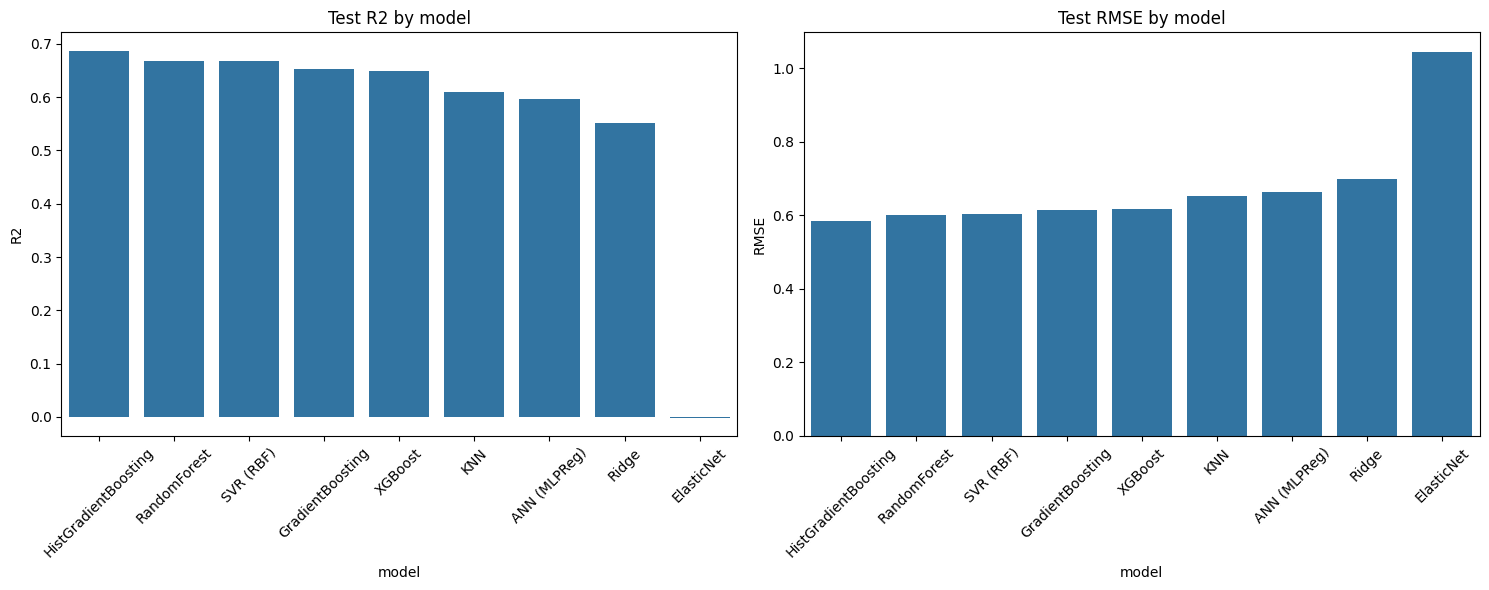

Uncleaned model metrics saved to 'LRRK2/model/lrrk2_uncleaned_model_metrics.csv'
Uncleaned model performance plot saved to 'LRRK2/model/lrrk2_uncleaned_model_performance.png'

Top 5 models (based on R2): ['HistGradientBoosting', 'RandomForest', 'SVR (RBF)', 'GradientBoosting', 'XGBoost']

✅ Multi-model evaluation completed successfully!


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib
from sklearn.model_selection import train_test_split, KFold
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import MACCSkeys # Import MACCSkeys for the new function
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import ElasticNet, Ridge
import xgboost as xgb


# Define the root directory for all results (re-defined for self-containment)
LRRK2_ROOT_DIR = 'LRRK2'

# Define the evaluate_models function here to ensure it's available
def evaluate_models(X_train, Y_train, X_test, Y_test, models_to_evaluate=None):
    """
    Trains and evaluates multiple machine learning models.

    Args:
        X_train (pd.DataFrame): Training features.
        Y_train (pd.Series): Training target.
        X_test (pd.DataFrame): Test features.
        Y_test (pd.Series): Test target.
        models_to_evaluate (list, optional): List of model names to evaluate.
                                            If None, all predefined models are evaluated.

    Returns:
        tuple: A tuple containing:
            - pd.DataFrame: A DataFrame with R2, RMSE metrics for each model.
            - matplotlib.figure.Figure: A figure object showing the R2 and RMSE plots.
    """
    all_models = {
        'RandomForest': RandomForestRegressor(random_state=42, n_jobs=-1),
        'GradientBoosting': GradientBoostingRegressor(random_state=42),
        'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
        'XGBoost': xgb.XGBRegressor(random_state=42, n_jobs=-1),
        'SVR (RBF)': SVR(kernel='rbf'),
        'ANN (MLPReg)': MLPRegressor(random_state=42, max_iter=500, hidden_layer_sizes=(100, 50)),
        'KNN': KNeighborsRegressor(n_neighbors=5),
        'ElasticNet': ElasticNet(random_state=42),
        'Ridge': Ridge(random_state=42)
    }

    if models_to_evaluate:
        models = {name: all_models[name] for name in models_to_evaluate if name in all_models}
    else:
        models = all_models

    results = []
    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    for name, model in models.items(): # Corrected loop to iterate through all models
        print(f"Training and cross-validating: {name}")
        # Cross-validation
        cv_r2_scores = []
        cv_rmse_scores = []

        for train_index, val_index in kf.split(X_train):
            X_train_fold, X_val_fold = X_train.iloc[train_index], X_train.iloc[val_index]
            Y_train_fold, Y_val_fold = Y_train.iloc[train_index], Y_train.iloc[val_index]

            model.fit(X_train_fold, Y_train_fold)
            Y_val_pred = model.predict(X_val_fold)
            cv_r2_scores.append(r2_score(Y_val_fold, Y_val_pred))
            cv_rmse_scores.append(np.sqrt(mean_squared_error(Y_val_fold, Y_val_pred)))

        # Final training on full training set and test evaluation
        model.fit(X_train, Y_train)
        Y_train_pred = model.predict(X_train)
        Y_test_pred = model.predict(X_test)

        train_r2 = r2_score(Y_train, Y_train_pred)
        test_r2 = r2_score(Y_test, Y_test_pred)
        test_rmse = np.sqrt(mean_squared_error(Y_test, Y_test_pred))

        results.append({
            'model': name,
            'cv_r2_mean': np.mean(cv_r2_scores),
            'cv_r2_std': np.std(cv_r2_scores),
            'cv_rmse_mean': np.mean(cv_rmse_scores),
            'cv_rmse_std': np.std(cv_rmse_scores),
            'train_r2': train_r2,
            'test_r2': test_r2,
            'test_rmse': test_rmse
        })

    results_df = pd.DataFrame(results).sort_values(by='test_r2', ascending=False).reset_index(drop=True)

    # Plotting results
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # Test R2 Plot
    sns.barplot(x='model', y='test_r2', data=results_df, ax=axes[0])
    axes[0].set_title('Test R2 by model')
    axes[0].set_ylabel('R2')
    axes[0].tick_params(axis='x', rotation=45)

    # Test RMSE Plot
    sns.barplot(x='model', y='test_rmse', data=results_df.sort_values(by='test_rmse', ascending=True), ax=axes[1])
    axes[1].set_title('Test RMSE by model')
    axes[1].set_ylabel('RMSE')
    axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    # plt.show() # Do not show here, return fig object

    return results_df, fig


# ==========================================================v
# === USER INPUT SECTION (you only change these paths) ===
# ==========================================================
target_col = "pIC50"                              # target column name (case-sensitive)
outdir = os.path.join(LRRK2_ROOT_DIR, 'model')
os.makedirs(outdir, exist_ok=True)

train_csv = os.path.join(outdir, "train.csv")  # training data with bioactivity column
test_csv  = os.path.join(outdir, "test.csv")   # test data with bioactivity column

# New paths for cleaned data and metrics (will be used in cell nQMUk9SACD7K)
cleaned_train_csv_path = os.path.join(outdir, 'lrrk2_train_cleaned.csv')
cleaned_test_csv_path = os.path.join(outdir, 'lrrk2_test_cleaned.csv')
cleaned_metrics_csv_path = os.path.join(outdir, 'lrrk2_cleaned_model_metrics.csv')
cleaned_metrics_plot_path = os.path.join(outdir, 'lrrk2_cleaned_model_performance.png')

# New paths for uncleaned metrics (to be saved here)
uncleaned_metrics_csv_path = os.path.join(outdir, 'lrrk2_uncleaned_model_metrics.csv')
uncleaned_metrics_plot_path = os.path.join(outdir, 'lrrk2_uncleaned_model_performance.png')
# ==========================================================

# --- Data Preparation from lrrk2_bioactivity_pIC50.csv ---

print("\n--- Preparing data from lrrk2_bioactivity_pIC50.csv ---")
# Load the pIC50 dataset
df_pIC50 = pd.read_csv('/content/LRRK2/lrrk2_bioactivity_pIC50.csv')

# Function to generate MACCS keys (copied from bba7437b for self-containment)
def generate_maccs_fingerprint(smiles):
    """
    Generates MACCS keys fingerprint for a given SMILES string.
    Returns a list of integers (0 or 1).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        fp = MACCSkeys.GenMACCSKeys(mol)
        return [int(x) for x in fp.ToBitString()]
    return None

# Apply fingerprint generation using MACCS keys
print("Generating MACCS keys...")
df_pIC50['fingerprints'] = df_pIC50['canonical_smiles'].apply(generate_maccs_fingerprint)

# Remove rows where fingerprint generation failed
df_pIC50.dropna(subset=['fingerprints'], inplace=True)

# Create a DataFrame from fingerprints
fingerprint_df = pd.DataFrame(df_pIC50['fingerprints'].tolist(), index=df_pIC50.index)
fingerprint_df.columns = [f'MACCS_{i}' for i in range(fingerprint_df.shape[1])] # Changed prefix

# Combine fingerprints with pIC50 values
ml_df = pd.concat([fingerprint_df, df_pIC50[['pIC50']]], axis=1)

# Save the full descriptor file (before correlation filtering)
full_descriptors_path = os.path.join(outdir, 'lrrk2_maccs_descriptors.csv')
ml_df.to_csv(full_descriptors_path, index=False)
print(f"Full MACCS key descriptors saved to '{full_descriptors_path}'")

print(f"Shape of molecular descriptor data: {ml_df.shape}")
print("First 5 rows of molecular descriptor data:")
print(ml_df.head())

# --- NEW CODE: Remove highly correlated descriptors ---
print("\n--- Removing highly correlated descriptors ---")
# Calculate the correlation matrix
corr_matrix = ml_df.iloc[:, :-1].corr().abs()

# Select upper triangle of correlation matrix
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than 0.95
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]

print(f"Found {len(to_drop)} highly correlated descriptors to remove.")

# Drop features
ml_df_reduced = ml_df.drop(columns=to_drop)

print(f"Shape of molecular descriptor data after removing correlated features: {ml_df_reduced.shape}")

# Split the data into training and testing sets
# Features (X) are the fingerprints, target (y) is pIC50
X = ml_df_reduced.drop('pIC50', axis=1)
y = ml_df_reduced['pIC50']

X_train_split, X_test_split, y_train_split, y_test_split = train_test_split(X, y, test_size=0.2, random_state=42)

# Recombine for saving as train.csv and test.csv
train_df_for_save = pd.concat([X_train_split, y_train_split], axis=1)
test_df_for_save = pd.concat([X_test_split, y_test_split], axis=1)

# Save the generated train and test CSVs
train_df_for_save.to_csv(train_csv, index=False)
test_df_for_save.to_csv(test_csv, index=False)
print(f"Training data saved to '{train_csv}' (Shape: {train_df_for_save.shape})")
print(f"Test data saved to '{test_csv}' (Shape: {test_df_for_save.shape})")
print("--------------------------------------------------\n")

# === 1. Load datasets ===
train_df = pd.read_csv(train_csv)
test_df = pd.read_csv(test_csv)

print(f"Train shape: {train_df.shape}, Test shape: {test_df.shape}")

# Separate features (X) and target (Y)
X_train = train_df.drop(columns=[target_col])
Y_train = train_df[target_col]
X_test = test_df.drop(columns=[target_col])
Y_test = test_df[target_col]

# === Evaluate Multiple Models ===
print("\n--- Evaluating Multiple Machine Learning Models ---")

# Call the evaluate_models function to train and evaluate various models
results_df, fig = evaluate_models(X_train, Y_train, X_test, Y_test)

print("\nModel Evaluation Results:")
print(results_df)

plt.show()

# Save uncleaned metrics dataframe and plot
results_df.to_csv(uncleaned_metrics_csv_path, index=False)
fig.savefig(uncleaned_metrics_plot_path)
print(f"Uncleaned model metrics saved to '{uncleaned_metrics_csv_path}'")
print(f"Uncleaned model performance plot saved to '{uncleaned_metrics_plot_path}'")

# Get top 5 models for further analysis (e.g., outlier detection)
top_5_models_names = results_df['model'].head(5).tolist()
print(f"\nTop 5 models (based on R2): {top_5_models_names}")

print("\n✅ Multi-model evaluation completed successfully!")


This cell sets up the machine learning pipeline. It imports various ML models, defines a function to evaluate them, prepares the pIC50 data by generating MACCS fingerprints, removes highly correlated features, splits the data into training and testing sets, and then evaluates multiple models, saving their performance metrics and plots.

Created or ensured existence of directory: 'LRRK2/refined_model'
Original Dataset Shape: (2712, 148)

Isolation Forest Outliers : 55
LOF Outliers              : 55
Consensus IF+LOF Outliers : 2


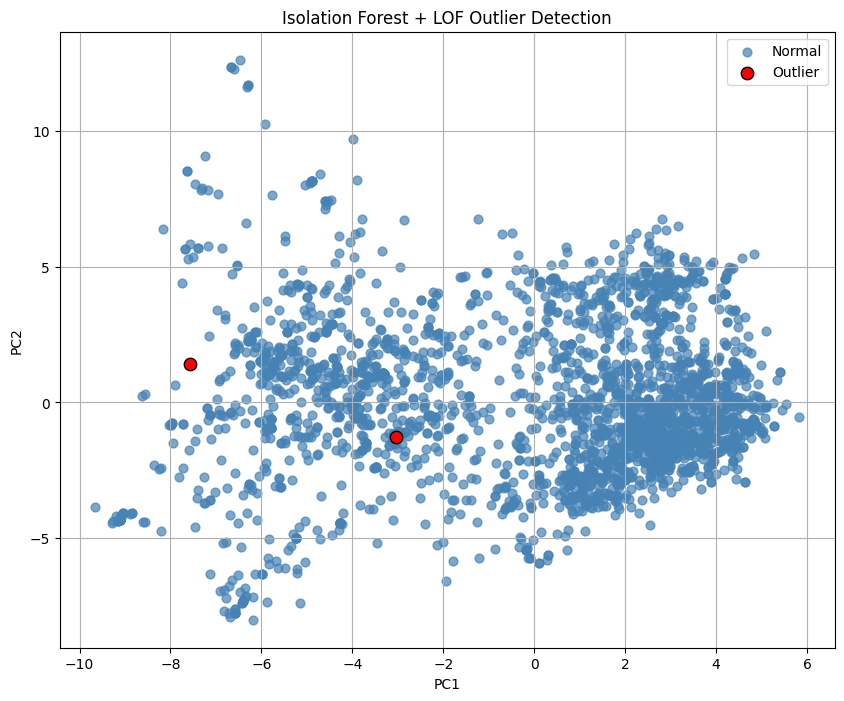

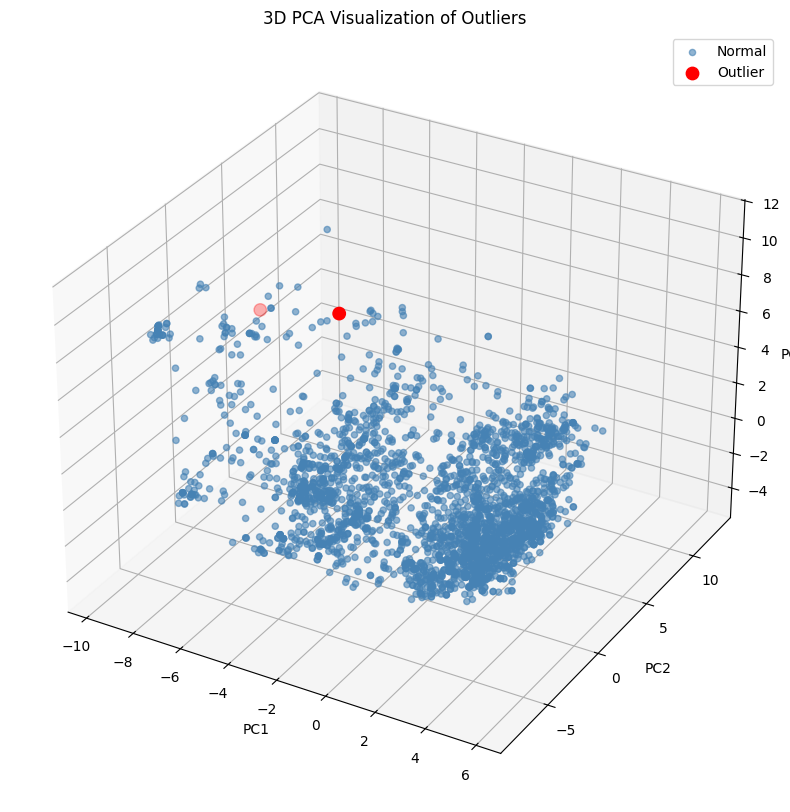


--- Identifying outliers based on prediction error (absolute error > 0.8) ---
Fitting HistGradientBoosting on combined data and calculating prediction errors...
Fitting RandomForest on combined data and calculating prediction errors...
Fitting SVR (RBF) on combined data and calculating prediction errors...
Fitting GradientBoosting on combined data and calculating prediction errors...
Fitting XGBoost on combined data and calculating prediction errors...
Number of outliers identified by prediction error: 598
Total outliers after combining IF+LOF and Prediction Error methods: 599

Dataset After Combined Outlier Removal: (2113, 148)

Training Shape : (1690, 148)
Testing Shape  : (423, 148)
Training and cross-validating: HistGradientBoosting
Training and cross-validating: RandomForest
Training and cross-validating: SVR (RBF)
Training and cross-validating: GradientBoosting
Training and cross-validating: XGBoost

Model Performance After Combined Outlier Removal
                  model  cv_r2

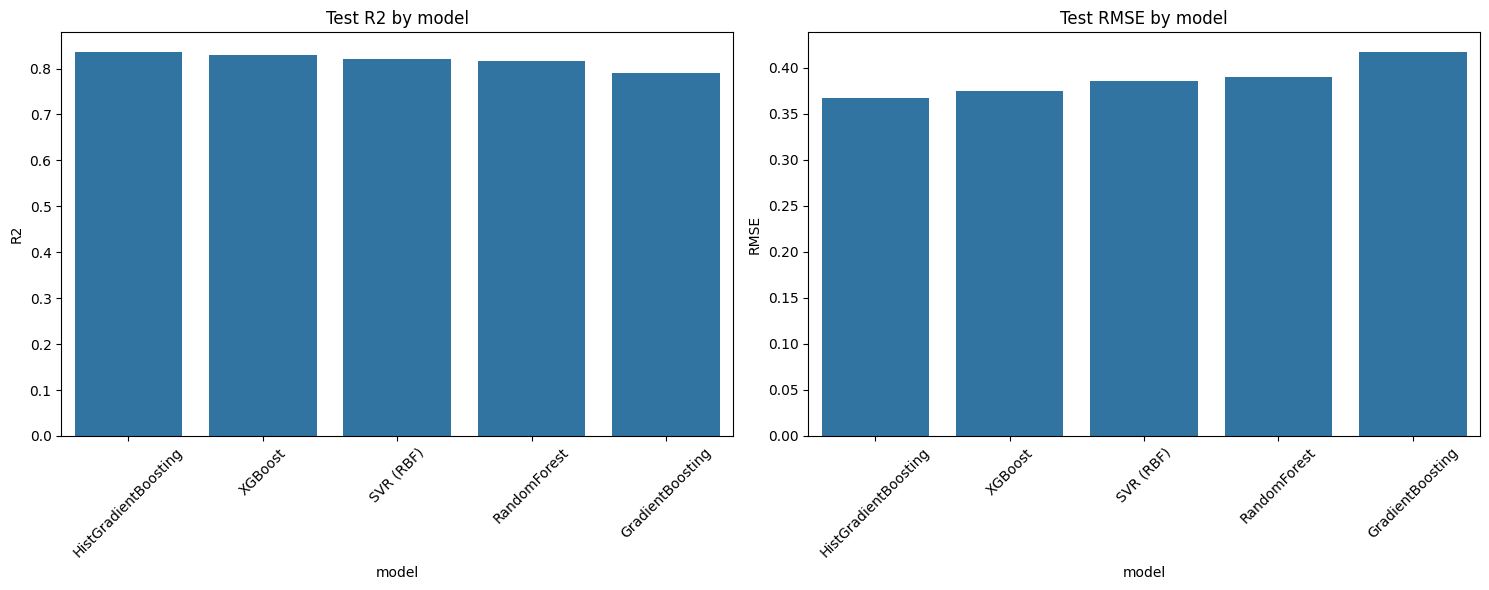

Cleaned training data saved to 'LRRK2/refined_model/lrrk2_train_cleaned.csv'
Cleaned testing data saved to 'LRRK2/refined_model/lrrk2_test_cleaned.csv'
Cleaned model metrics saved to 'LRRK2/refined_model/lrrk2_cleaned_model_metrics.csv'
Cleaned model performance plot saved to 'LRRK2/refined_model/lrrk2_cleaned_model_performance.png'

✅ Outlier removal and re-evaluation completed successfully with prediction error method included.


In [ ]:
# ============================================================
# OUTLIER DETECTION USING ISOLATION FOREST + LOF
# Recommended for QSAR and Drug Discovery
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os # Ensure os is imported here as well

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, HistGradientBoostingRegressor, RandomForestRegressor, GradientBoostingRegressor # Added HistGB, RF, GB for prediction error detection
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR # Added SVR for prediction error detection
import xgboost as xgb # Added XGBoost for prediction error detection

# Define the root directory for all results (re-defined for self-containment)
LRRK2_ROOT_DIR = 'LRRK2'

# Define new output directory for refined model results
refined_model_outdir = os.path.join(LRRK2_ROOT_DIR, 'refined_model')
os.makedirs(refined_model_outdir, exist_ok=True)
print(f"Created or ensured existence of directory: '{refined_model_outdir}'")

# Update paths to save cleaned data and metrics to the new 'refined_model_outdir'
cleaned_train_csv_path = os.path.join(refined_model_outdir, 'lrrk2_train_cleaned.csv')
cleaned_test_csv_path = os.path.join(refined_model_outdir, 'lrrk2_test_cleaned.csv')
cleaned_metrics_csv_path = os.path.join(refined_model_outdir, 'lrrk2_cleaned_model_metrics.csv')
cleaned_metrics_plot_path = os.path.join(refined_model_outdir, 'lrrk2_cleaned_model_performance.png')

# ============================================================
# Combine Train and Test Data
# ============================================================

X_combined = pd.concat([X_train, X_test], axis=0)
y_combined = pd.concat([Y_train, Y_test], axis=0)

print("Original Dataset Shape:", X_combined.shape)

# ============================================================
# Standardization
# ============================================================

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_combined)

# ============================================================
# Isolation Forest
# ============================================================

iso = IsolationForest(
    contamination=0.02,
    n_estimators=300,
    random_state=42
)

iso_labels = iso.fit_predict(X_scaled)

# +1 = Normal
# -1 = Outlier

# ============================================================
# Local Outlier Factor
# ============================================================

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.02
)

lof_labels = lof.fit_predict(X_scaled)

# ============================================================
# Consensus Outlier Detection (Isolation Forest + LOF)
# ============================================================

outlier_mask_if_lof = (iso_labels == -1) & (lof_labels == -1)

print("\nIsolation Forest Outliers :", np.sum(iso_labels==-1))
print("LOF Outliers              :", np.sum(lof_labels==-1))
print("Consensus IF+LOF Outliers :", np.sum(outlier_mask_if_lof))

# ============================================================
# PCA Visualization (2D) - showing IF+LOF outliers
# ============================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10,8))

plt.scatter(
    X_pca[~outlier_mask_if_lof,0],
    X_pca[~outlier_mask_if_lof,1],
    c='steelblue',
    s=40,
    alpha=0.7,
    label='Normal'
)

plt.scatter(
    X_pca[outlier_mask_if_lof,0],
    X_pca[outlier_mask_if_lof,1],
    c='red',
    s=80,
    edgecolor='black',
    label='Outlier'
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Isolation Forest + LOF Outlier Detection")
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# PCA Visualization (3D) - showing IF+LOF outliers
# ============================================================

from mpl_toolkits.mplot3d import Axes3D

pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

fig = plt.figure(figsize=(12,10))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    X_pca3[~outlier_mask_if_lof,0],
    X_pca3[~outlier_mask_if_lof,1],
    X_pca3[~outlier_mask_if_lof,2],
    color='steelblue',
    alpha=0.6,
    label='Normal'
)

ax.scatter(
    X_pca3[outlier_mask_if_lof,0],
    X_pca3[outlier_mask_if_lof,1],
    X_pca3[outlier_mask_if_lof,2],
    color='red',
    s=80,
    label='Outlier'
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D PCA Visualization of Outliers")
ax.legend()

plt.show()

# ============================================================
# NEW: Outlier Detection based on Prediction Error
# ============================================================
# Using the model types defined in evaluate_models function from bnOtB-FYVH0e

all_models_for_error_detection = {
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
    'RandomForest': RandomForestRegressor(random_state=42, n_jobs=1),
    'SVR (RBF)': SVR(kernel='rbf'),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': xgb.XGBRegressor(random_state=42, n_jobs=1),
}

# Filter for only the top 5 models, assuming top_5_models_names is available
models_to_check_error = {name: all_models_for_error_detection[name] for name in top_5_models_names if name in all_models_for_error_detection}

pred_error_outlier_mask = np.zeros(len(y_combined), dtype=bool)
prediction_error_threshold = 0.8 # User specified threshold

print(f"\n--- Identifying outliers based on prediction error (absolute error > {prediction_error_threshold}) ---")

# Iterate through the top 5 models, train on X_combined, and check prediction error
# A sample is flagged as an outlier if its absolute prediction error from *any* of these models exceeds the threshold.
for name, model in models_to_check_error.items():
    print(f"Fitting {name} on combined data and calculating prediction errors...")
    model.fit(X_combined, y_combined) # Train on full combined data
    predictions = model.predict(X_combined)
    abs_errors = np.abs(y_combined.values - predictions)
    pred_error_outlier_mask = pred_error_outlier_mask | (abs_errors > prediction_error_threshold)

print(f"Number of outliers identified by prediction error: {np.sum(pred_error_outlier_mask)}")

# ============================================================
# Combine all outlier masks
# An instance is considered an outlier if flagged by IF+LOF OR by Prediction Error
# ============================================================

final_outlier_mask = outlier_mask_if_lof | pred_error_outlier_mask
print(f"Total outliers after combining IF+LOF and Prediction Error methods: {np.sum(final_outlier_mask)}")

# ============================================================
# Remove Combined Outliers
# ============================================================

X_cleaned = X_combined.loc[~final_outlier_mask]
y_cleaned = y_combined.loc[~final_outlier_mask]

print(f"\nDataset After Combined Outlier Removal: {X_cleaned.shape}")

# ============================================================
# Split Again
# ============================================================

X_train_cleaned, X_test_cleaned, Y_train_cleaned, Y_test_cleaned = train_test_split(
    X_cleaned,
    y_cleaned,
    test_size=0.20,
    random_state=42
)

print("\nTraining Shape :", X_train_cleaned.shape)
print("Testing Shape  :", X_test_cleaned.shape)

# ============================================================
# Re-evaluate Best Models on Cleaned Data
# ============================================================

results_df_cleaned, fig_cleaned = evaluate_models(
    X_train_cleaned,
    Y_train_cleaned,
    X_test_cleaned,
    Y_test_cleaned,
    models_to_evaluate=top_5_models_names
)

print("\nModel Performance After Combined Outlier Removal")
print(results_df_cleaned)

plt.show()

# Save cleaned datasets to the specified paths
train_cleaned_df = pd.concat([X_train_cleaned, Y_train_cleaned], axis=1)
test_cleaned_df = pd.concat([X_test_cleaned, Y_test_cleaned], axis=1)

train_cleaned_df.to_csv(cleaned_train_csv_path, index=False)
test_cleaned_df.to_csv(cleaned_test_csv_path, index=False)

print(f"Cleaned training data saved to '{cleaned_train_csv_path}'")
print(f"Cleaned testing data saved to '{cleaned_test_csv_path}'")

# Save cleaned metrics dataframe and plot
results_df_cleaned.to_csv(cleaned_metrics_csv_path, index=False)
fig_cleaned.savefig(cleaned_metrics_plot_path)
print(f"Cleaned model metrics saved to '{cleaned_metrics_csv_path}'")
print(f"Cleaned model performance plot saved to '{cleaned_metrics_plot_path}'")

print("\n✅ Outlier removal and re-evaluation completed successfully with prediction error method included.")


This cell performs outlier detection using a combination of Isolation Forest, Local Outlier Factor (LOF), and prediction error from the top-performing models. It visualizes the outliers using 2D and 3D PCA plots, removes identified outliers, and re-evaluates the models on the cleaned data, saving the new metrics and plots.


--- Processing HistGradientBoosting Model for Refined Data ---

HistGradientBoosting Model saved to: LRRK2/refined_model/hist_gradient_boosting_model.joblib
Predictions for HistGradientBoosting saved to 'LRRK2/refined_model/train_predictions_hgb.csv' and 'LRRK2/refined_model/test_predictions_hgb.csv'.


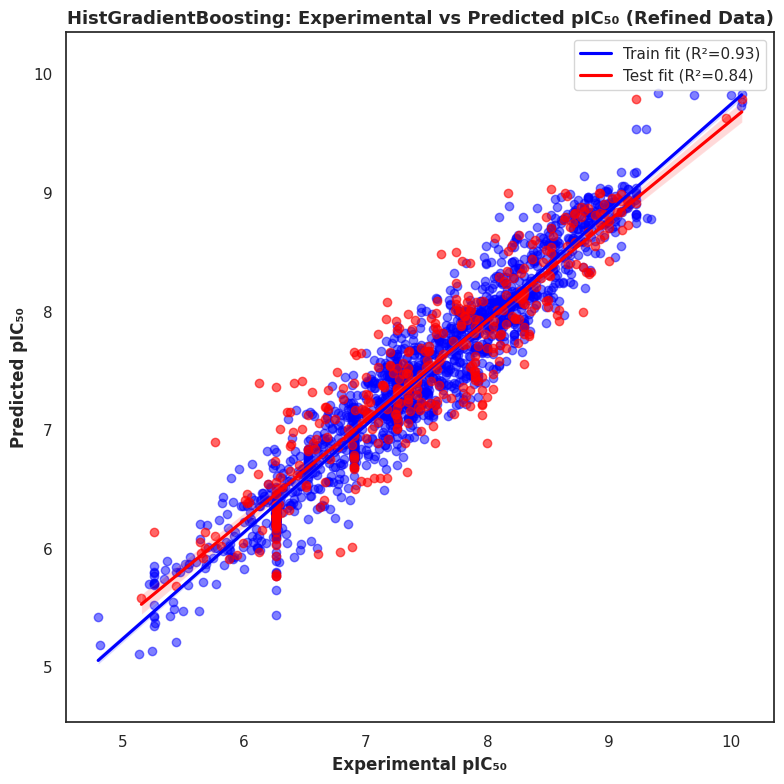


Plot saved to: LRRK2/refined_model/Experimental_vs_Predicted_pIC50_HGB_refined.png
Metrics summary saved to: LRRK2/refined_model/hgb_metrics_summary_refined.csv

✅ HistGradientBoosting model analysis for refined data completed successfully!


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.ensemble import HistGradientBoostingRegressor # Import the specific model
from sklearn.metrics import r2_score, mean_squared_error # Ensure these are imported

# Assuming the following variables are available from previous cells in the kernel state:
# X_train_cleaned, Y_train_cleaned, X_test_cleaned, Y_test_cleaned
# refined_model_outdir (which is 'LRRK2/refined_model')
# results_df_cleaned (containing metrics for all models on cleaned data)

# --- 1. Select and train the HistGradientBoosting model ---
print("\n--- Processing HistGradientBoosting Model for Refined Data ---")

hgb_model = HistGradientBoostingRegressor(random_state=42)
hgb_model.fit(X_train_cleaned, Y_train_cleaned)

# --- 2. Generate predictions ---
Y_train_pred_hgb = hgb_model.predict(X_train_cleaned)
Y_test_pred_hgb = hgb_model.predict(X_test_cleaned)

# --- 3. Extract metrics for HistGradientBoosting from results_df_cleaned ---
hgb_metrics_row = results_df_cleaned[results_df_cleaned['model'] == 'HistGradientBoosting'].iloc[0]

train_metrics_hgb = {'r2': hgb_metrics_row['train_r2'], 'rmse': np.sqrt(mean_squared_error(Y_train_cleaned, Y_train_pred_hgb))}
test_metrics_hgb = {'r2': hgb_metrics_row['test_r2'], 'rmse': hgb_metrics_row['test_rmse']}

# Set the output directory to the refined model directory
current_outdir = refined_model_outdir

# --- 4. Save the model ---
model_path_hgb = os.path.join(current_outdir, "hist_gradient_boosting_model.joblib")
joblib.dump(hgb_model, model_path_hgb)
print("\nHistGradientBoosting Model saved to:", model_path_hgb)

# --- 5. Save predictions ---
train_preds_hgb = pd.DataFrame({
    "Experimental_pIC50": Y_train_cleaned,
    "Predicted_pIC50": Y_train_pred_hgb
})
test_preds_hgb = pd.DataFrame({
    "Experimental_pIC50": Y_test_cleaned,
    "Predicted_pIC50": Y_test_pred_hgb
})

train_preds_path_hgb = os.path.join(current_outdir, "train_predictions_hgb.csv")
test_preds_path_hgb = os.path.join(current_outdir, "test_predictions_hgb.csv")

train_preds_hgb.to_csv(train_preds_path_hgb, index=False)
test_preds_hgb.to_csv(test_preds_path_hgb, index=False)
print(f"Predictions for HistGradientBoosting saved to '{train_preds_path_hgb}' and '{test_preds_path_hgb}'.")

# --- 6. Plot Experimental vs Predicted pIC50 ---
sns.set(style="white", color_codes=True)
plt.figure(figsize=(8,8))

# Training set (blue)
sns.regplot(
    x=Y_train_cleaned,
    y=Y_train_pred_hgb,
    scatter_kws={'alpha':0.5, 'color':'blue'},
    line_kws={'color':'blue', 'label':f"Train fit (R²={train_metrics_hgb['r2']:.2f})"}
)

# Test set (red)
sns.regplot(
    x=Y_test_cleaned,
    y=Y_test_pred_hgb,
    scatter_kws={'alpha':0.6, 'color':'red'},
    line_kws={'color':'red', 'label':f"Test fit (R²={test_metrics_hgb['r2']:.2f})"}
)

# Calculate combined min/max for axis limits
min_val = min(Y_train_cleaned.min(), Y_test_cleaned.min(), Y_train_pred_hgb.min(), Y_test_pred_hgb.min())
max_val = max(Y_train_cleaned.max(), Y_test_cleaned.max(), Y_train_pred_hgb.max(), Y_test_pred_hgb.max())

# Add a small buffer to the limits
buffer = (max_val - min_val) * 0.05
lims = [min_val - buffer, max_val + buffer]

plt.xlabel('Experimental pIC₅₀', fontsize=12, fontweight='bold')
plt.ylabel('Predicted pIC₅₀', fontsize=12, fontweight='bold')
plt.title('HistGradientBoosting: Experimental vs Predicted pIC₅₀ (Refined Data)', fontsize=13, fontweight='bold')
plt.xlim(lims)
plt.ylim(lims)
plt.legend(loc='best')
plt.tight_layout()

plot_path_hgb = os.path.join(current_outdir, "Experimental_vs_Predicted_pIC50_HGB_refined.png")
plt.savefig(plot_path_hgb, dpi=150)
plt.show()

print("\nPlot saved to:", plot_path_hgb)

# --- 7. Save metrics summary ---
metrics_df_hgb = pd.DataFrame([
    {"Dataset": "Train", "R2": train_metrics_hgb['r2'], "RMSE": train_metrics_hgb['rmse']},
    {"Dataset": "Test", "R2": test_metrics_hgb['r2'], "RMSE": test_metrics_hgb['rmse']}
])
metrics_path_hgb = os.path.join(current_outdir, "hgb_metrics_summary_refined.csv")
metrics_df_hgb.to_csv(metrics_path_hgb, index=False)
print("Metrics summary saved to:", metrics_path_hgb)

print("\n✅ HistGradientBoosting model analysis for refined data completed successfully!")

Applicability Domain Threshold = 3.5229768150427954
Inside AD : 402
Outside AD: 21
Applicability Domain table saved.


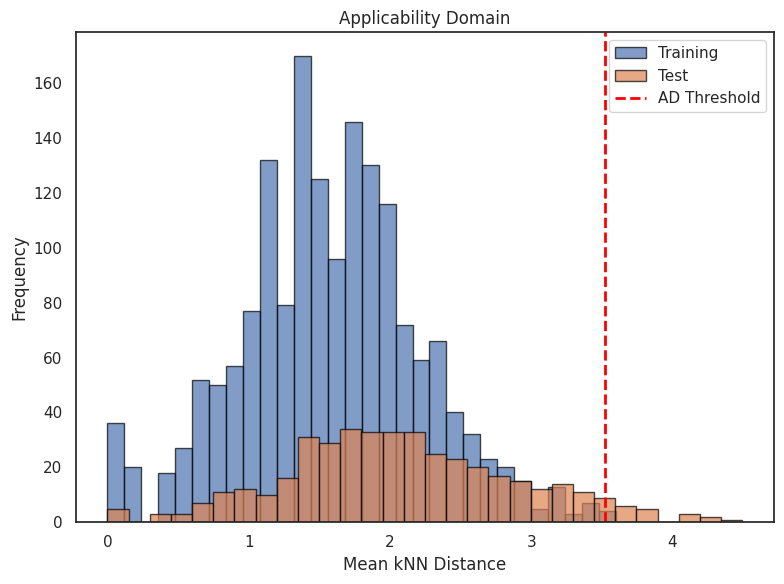

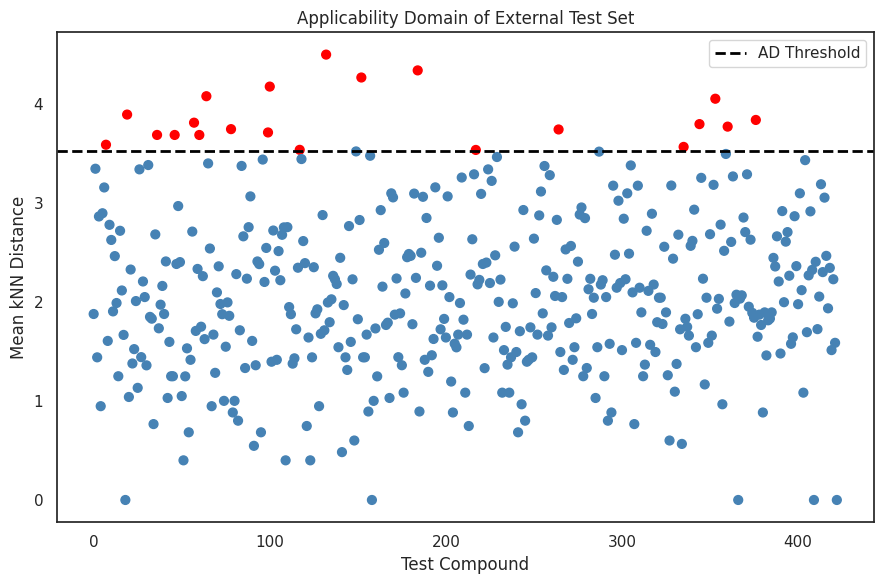


Applicability Domain Summary
Training compounds : 1690
Test compounds     : 423
Inside AD          : 402
Outside AD         : 21


In [ ]:
# ============================================================
# Applicability Domain Analysis (kNN Distance Method)
# ============================================================

from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# ============================================================
# Train Final HistGradientBoosting Model
# ============================================================

from sklearn.ensemble import HistGradientBoostingRegressor

final_model = HistGradientBoostingRegressor(
    random_state=42
)

final_model.fit(
    X_train_cleaned,
    Y_train_cleaned
)


# ============================================================
# Predictions
# ============================================================

train_pred = final_model.predict(X_train_cleaned)
test_pred = final_model.predict(X_test_cleaned)


# ============================================================
# kNN Applicability Domain
# ============================================================

k = 5

knn = NearestNeighbors(
    n_neighbors=k,
    metric="euclidean"
)

knn.fit(X_train_cleaned)

train_distance, _ = knn.kneighbors(X_train_cleaned)
test_distance, _ = knn.kneighbors(X_test_cleaned)

train_mean_distance = train_distance.mean(axis=1)
test_mean_distance = test_distance.mean(axis=1)


# ============================================================
# Applicability Domain Threshold
# ============================================================

AD_threshold = (
    train_mean_distance.mean()
    + 3 * train_mean_distance.std()
)

print("Applicability Domain Threshold =", AD_threshold)


# ============================================================
# Inside / Outside Applicability Domain
# ============================================================

inside_AD = test_mean_distance <= AD_threshold

outside_AD = test_mean_distance > AD_threshold

print("Inside AD :", np.sum(inside_AD))
print("Outside AD:", np.sum(outside_AD))

# ============================================================
# Save AD Results
# ============================================================

AD_results = pd.DataFrame({

    "Experimental_pIC50":Y_test_cleaned.values,

    "Predicted_pIC50":test_pred,

    "Mean_kNN_Distance":test_mean_distance,

    "Inside_AD":inside_AD

})

AD_results.to_csv(

    os.path.join(

        refined_model_outdir,

        "Applicability_Domain.csv"

    ),

    index=False

)

print("Applicability Domain table saved.")

# ============================================================
# Applicability Domain Distribution
# ============================================================

plt.figure(figsize=(8,6))

plt.hist(

    train_mean_distance,

    bins=30,

    alpha=0.7,

    label="Training",

    edgecolor="black"

)

plt.hist(

    test_mean_distance,

    bins=30,

    alpha=0.7,

    label="Test",

    edgecolor="black"

)

plt.axvline(

    AD_threshold,

    color="red",

    linestyle="--",

    linewidth=2,

    label="AD Threshold"

)

plt.xlabel("Mean kNN Distance")

plt.ylabel("Frequency")

plt.title("Applicability Domain")

plt.legend()

plt.tight_layout()

plt.savefig(

    os.path.join(

        refined_model_outdir,

        "Applicability_Domain_Histogram.png"

    ),

    dpi=600

)

plt.show()

# ============================================================
# Test Compound Applicability Domain
# ============================================================

plt.figure(figsize=(9,6))

colors = np.where(

    inside_AD,

    "steelblue",

    "red"

)

plt.scatter(

    np.arange(len(test_mean_distance)),

    test_mean_distance,

    c=colors,

    s=40

)

plt.axhline(

    AD_threshold,

    color="black",

    linestyle="--",

    linewidth=2,

    label="AD Threshold"

)

plt.xlabel("Test Compound")

plt.ylabel("Mean kNN Distance")

plt.title("Applicability Domain of External Test Set")

plt.legend()

plt.tight_layout()

plt.savefig(

    os.path.join(

        refined_model_outdir,

        "Applicability_Domain_Test_Set.png"

    ),

    dpi=600

)

plt.show()


# ============================================================
# Summary
# ============================================================

print("\n==============================")

print("Applicability Domain Summary")

print("==============================")

print("Training compounds :", len(train_mean_distance))

print("Test compounds     :", len(test_mean_distance))

print("Inside AD          :", np.sum(inside_AD))

print("Outside AD         :", np.sum(outside_AD))

print("==============================")


This cell focuses on the HistGradientBoosting model, which was identified as a top performer. It trains the model on the cleaned data, generates predictions, calculates and saves performance metrics, saves the trained model, and creates a scatter plot showing experimental vs. predicted pIC50 values.


--- Generating Feature Importance Plot for HistGradientBoosting (Refined Data) using Permutation Importance ---
Calculating permutation importances...
Top 10 Features by HistGradientBoosting Permutation Importance:
     Feature  Importance
0   MACCS_38    0.138752
1   MACCS_22    0.134924
2  MACCS_153    0.098509
3   MACCS_66    0.096825
4   MACCS_69    0.052852
5  MACCS_147    0.050785
6   MACCS_75    0.031262
7  MACCS_129    0.029090
8  MACCS_152    0.026660
9  MACCS_131    0.018780


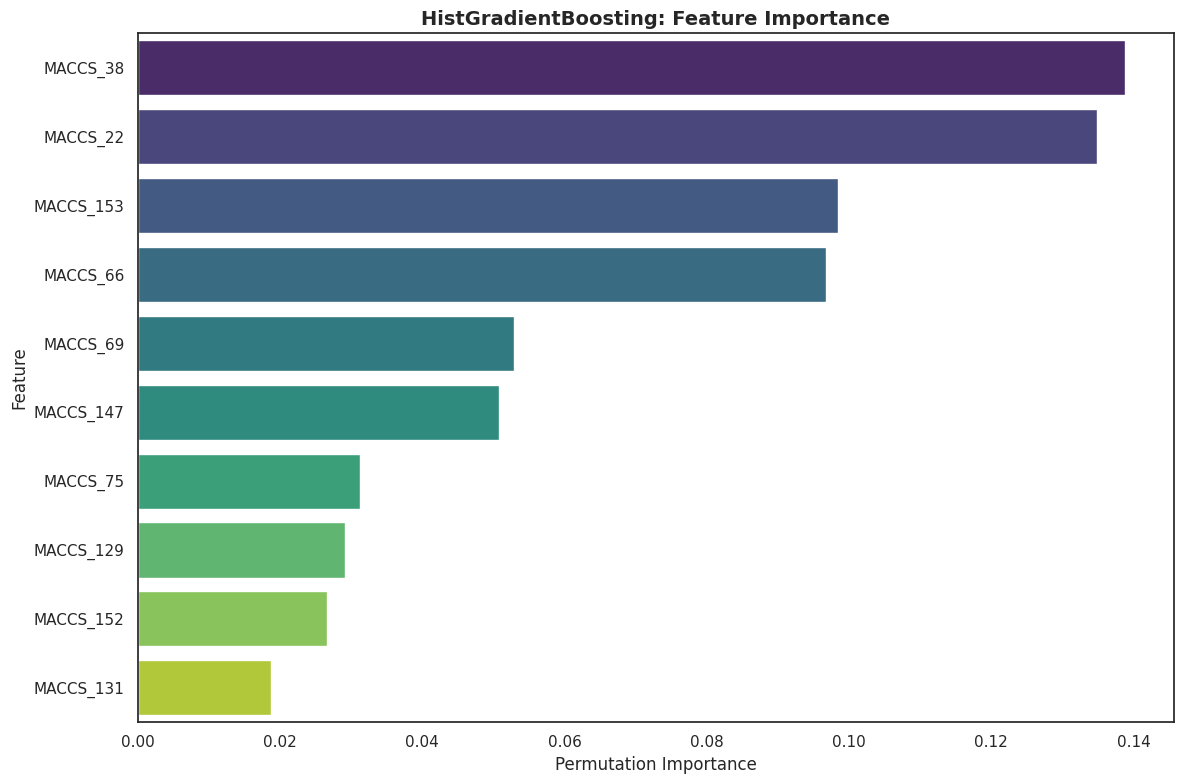

Feature importance plot saved to 'LRRK2/refined_model/lrrk2_hgb_feature_importance_plot.png'

✅ HistGradientBoosting feature importance analysis completed successfully!


<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance # Import for permutation importance

# Assuming X_cleaned, y_cleaned, and refined_model_outdir are available
# from previous cell executions in the kernel state.

print("\n--- Generating Feature Importance Plot for HistGradientBoosting (Refined Data) using Permutation Importance ---")

# 1. Initialize and train the HistGradientBoostingRegressor model
# Using the cleaned combined data (X_cleaned, y_cleaned)
hgb_model_for_importance = HistGradientBoostingRegressor(random_state=42)
hgb_model_for_importance.fit(X_cleaned, y_cleaned)

# 2. Calculate Permutation Importances
# Note: This can be computationally intensive for large datasets/models
print("Calculating permutation importances...")
perm_importance = permutation_importance(
    hgb_model_for_importance,
    X_cleaned,
    y_cleaned,
    n_repeats=10, # Number of times to permute a feature
    random_state=42,
    n_jobs=-1 # Use all available CPU cores
)

# 3. Create a DataFrame for better visualization
importance_df = pd.DataFrame({
    'Feature': X_cleaned.columns,
    'Importance': perm_importance.importances_mean
})

# Sort by importance in descending order
importance_df = importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("Top 10 Features by HistGradientBoosting Permutation Importance:")
print(importance_df.head(10))

# 4. Create a colorful bar plot (VIP-like style)
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', hue='Feature', data=importance_df.head(10), palette='viridis', legend=False) # Display top 10 features, added hue and legend=False
plt.title('HistGradientBoosting: Feature Importance', fontsize=14, fontweight='bold')
plt.xlabel('Permutation Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

# 5. Save the plot to the refined model directory
importance_plot_path = os.path.join(refined_model_outdir, 'lrrk2_hgb_feature_importance_plot.png')
plt.savefig(importance_plot_path, dpi=600)
print(f"Feature importance plot saved to '{importance_plot_path}'")

print("\n✅ HistGradientBoosting feature importance analysis completed successfully!")


This cell calculates and visualizes feature importance for the HistGradientBoosting model using permutation importance. It identifies the most influential MACCS features in predicting pIC50 and displays them in a bar plot, saving the plot to a file.

Running SHAP Analysis...


 98%|===================| 2077/2113 [00:16<00:00]       

SHAP values calculated.


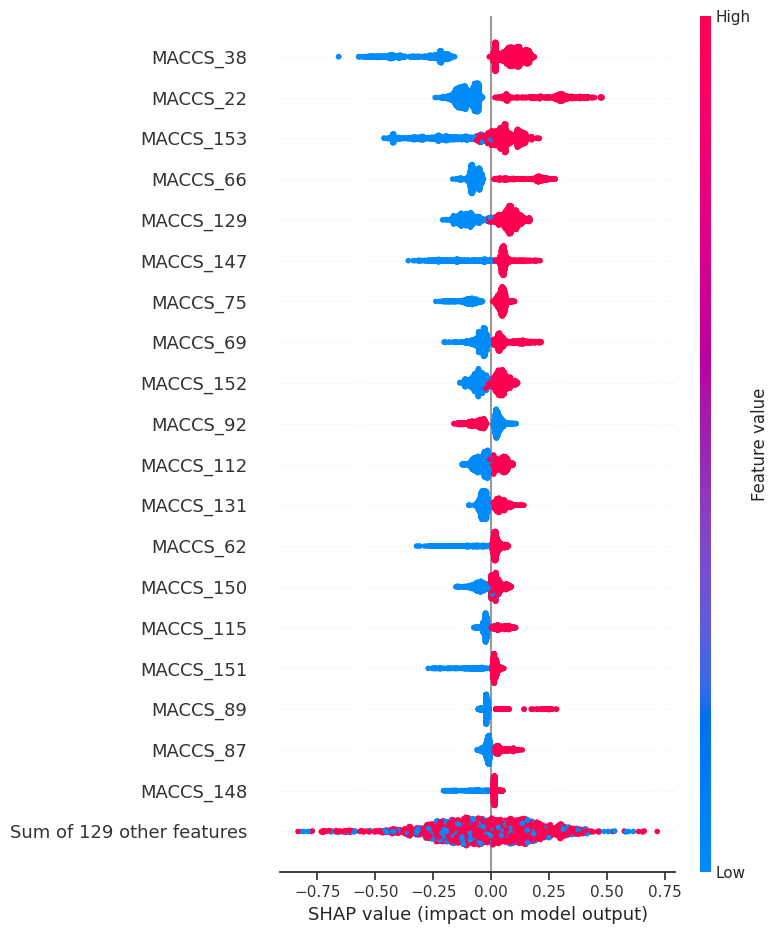

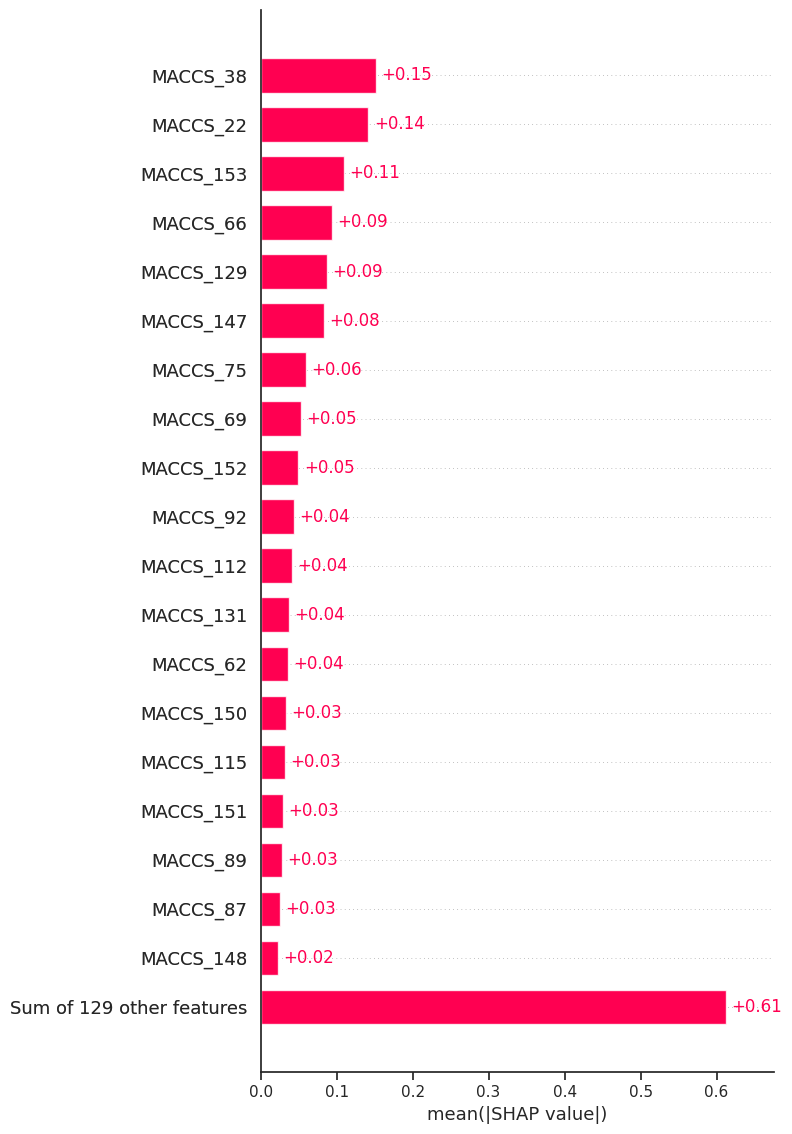


Top 20 Important Descriptors

    Descriptor  Mean_SHAP
36    MACCS_38   0.151236
22    MACCS_22   0.141814
134  MACCS_153   0.109546
57    MACCS_66   0.093600
113  MACCS_129   0.087704
128  MACCS_147   0.083113
64    MACCS_75   0.059534
59    MACCS_69   0.053490
133  MACCS_152   0.049773
80    MACCS_92   0.044047
97   MACCS_112   0.041656
115  MACCS_131   0.037215
54    MACCS_62   0.035765
131  MACCS_150   0.033472
100  MACCS_115   0.031933
132  MACCS_151   0.029678
77    MACCS_89   0.027757
75    MACCS_87   0.025222
129  MACCS_148   0.022804
67    MACCS_79   0.022607


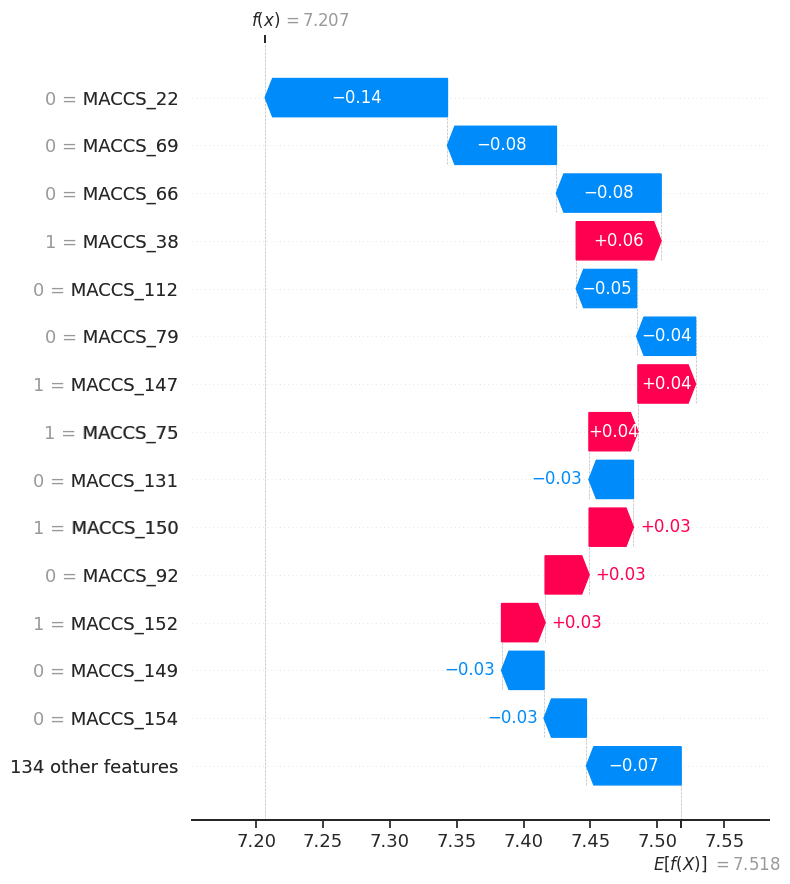


Generating dependence plots...



<Figure size 600x500 with 0 Axes>

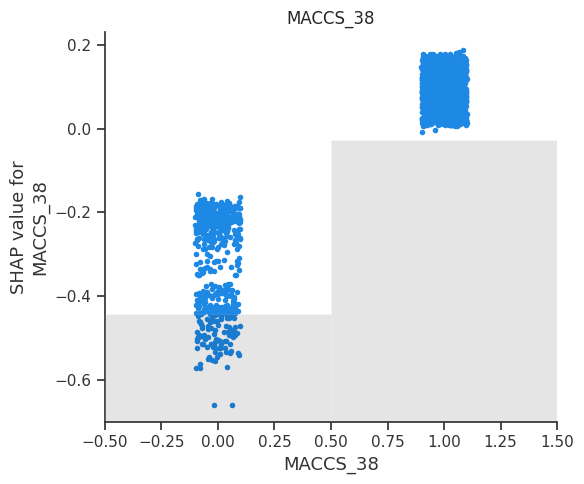

<Figure size 600x500 with 0 Axes>

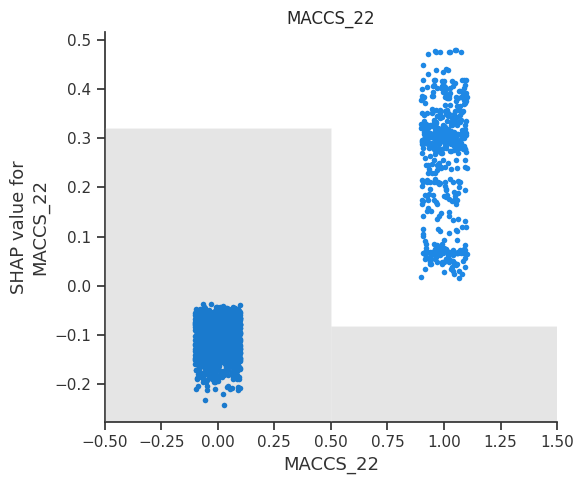

<Figure size 600x500 with 0 Axes>

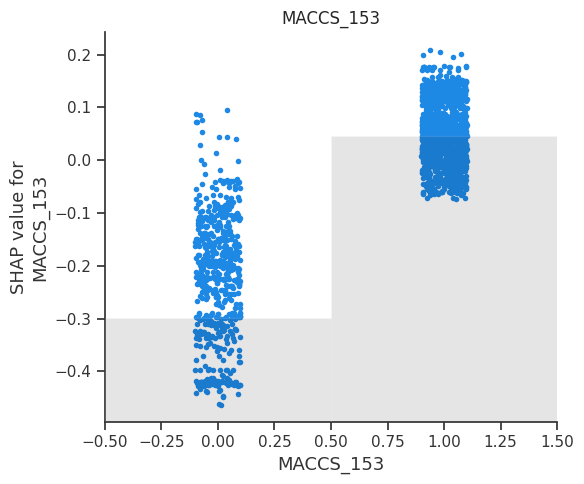

<Figure size 600x500 with 0 Axes>

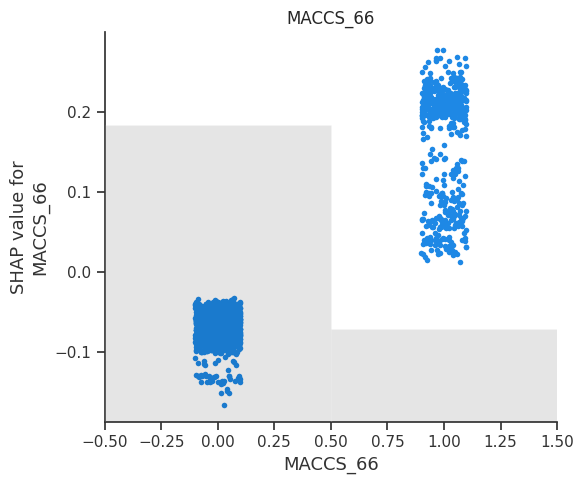

<Figure size 600x500 with 0 Axes>

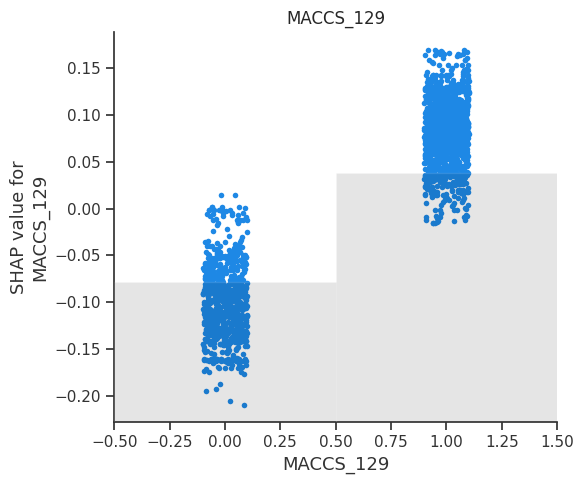


SHAP ANALYSIS COMPLETED

Results saved in:
LRRK2/refined_model/SHAP_Results

Generated Files:

SHAP_Beeswarm.png
SHAP_BarPlot.png
SHAP_Waterfall.png
Top5 Dependence Plots
SHAP_FeatureImportance.csv
SHAP_Values.csv



In [ ]:
# =============================================================================
# SHAP ANALYSIS FOR HistGradientBoostingRegressor
# =============================================================================

# Install SHAP (if needed)
!pip install -q shap

import os
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =============================================================================
# Load trained model
# =============================================================================

model_path = os.path.join(
    refined_model_outdir,
    "hist_gradient_boosting_model.joblib"
)

model = joblib.load(model_path)

print("="*70)
print("Running SHAP Analysis...")
print("="*70)

# =============================================================================
# Create background dataset
# =============================================================================

background = shap.sample(
    X_cleaned,
    200,
    random_state=42
)

# =============================================================================
# Create SHAP explainer
# =============================================================================

explainer = shap.Explainer(
    model,
    background
)

# =============================================================================
# Calculate SHAP values
# =============================================================================

shap_values = explainer(X_cleaned)

print("SHAP values calculated.")

# =============================================================================
# Create output directory
# =============================================================================

shap_dir = os.path.join(
    refined_model_outdir,
    "SHAP_Results"
)

os.makedirs(shap_dir, exist_ok=True)

# =============================================================================
# 1. SHAP Beeswarm Plot
# =============================================================================

plt.figure(figsize=(10,8))

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        shap_dir,
        "SHAP_Beeswarm.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# 2. SHAP Feature Importance Bar Plot
# =============================================================================

plt.figure(figsize=(8,6))

shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        shap_dir,
        "SHAP_BarPlot.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# 3. Feature Importance Table
# =============================================================================

importance = pd.DataFrame({

    "Descriptor": X_cleaned.columns,

    "Mean_SHAP":
        np.abs(shap_values.values).mean(axis=0)

})

importance = importance.sort_values(
    by="Mean_SHAP",
    ascending=False
)

importance.to_csv(

    os.path.join(
        shap_dir,
        "SHAP_FeatureImportance.csv"
    ),

    index=False

)

print("\nTop 20 Important Descriptors\n")

print(importance.head(20))

# =============================================================================
# 4. Waterfall Plot
# =============================================================================

sample = 0

plt.figure(figsize=(8,6))

shap.plots.waterfall(

    shap_values[sample],

    max_display=15,

    show=False

)

plt.tight_layout()

plt.savefig(

    os.path.join(
        shap_dir,
        "SHAP_Waterfall.png"
    ),

    dpi=300,

    bbox_inches="tight"

)

plt.show()

# =============================================================================
# 5. Dependence Plots (Top 5 Features)
# =============================================================================

top_features = importance.head(5)["Descriptor"].tolist()

print("\nGenerating dependence plots...\n")

for feature in top_features:

    plt.figure(figsize=(6,5))

    shap.plots.scatter(

        shap_values[:, feature],

        show=False

    )

    plt.title(feature)

    plt.tight_layout()

    plt.savefig(

        os.path.join(
            shap_dir,
            f"{feature}_dependence.png"
        ),

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()

# =============================================================================
# 6. Force Plot (Interactive)
# =============================================================================

shap.initjs()

force_plot = shap.force_plot(

    explainer.expected_value,

    shap_values.values[0],

    X_cleaned.iloc[0]

)

display(force_plot)

# =============================================================================
# 7. Save SHAP values
# =============================================================================

shap_df = pd.DataFrame(

    shap_values.values,

    columns=X_cleaned.columns

)

shap_df.to_csv(

    os.path.join(
        shap_dir,
        "SHAP_Values.csv"
    ),

    index=False

)

# =============================================================================
# Finished
# =============================================================================

print("\n" + "="*70)
print("SHAP ANALYSIS COMPLETED")
print("="*70)

print(f"\nResults saved in:\n{shap_dir}")

print("\nGenerated Files:")

print("""
SHAP_Beeswarm.png
SHAP_BarPlot.png
SHAP_Waterfall.png
Top5 Dependence Plots
SHAP_FeatureImportance.csv
SHAP_Values.csv
""")


This cell performs SHAP (SHapley Additive exPlanations) analysis on the trained HistGradientBoosting model. It calculates SHAP values to explain individual predictions, generates several SHAP plots (beeswarm, bar, waterfall, dependence), and saves the results, including a feature importance table, to a dedicated directory.

In [ ]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.DataStructs import TanimotoSimilarity
import os
import numpy as np

print("--- Calculating Tanimoto Similarity from raw bioactivity data ---")

# Define the path to the raw bioactivity data
raw_data_path = '/content/LRRK2/lrrk2_bioactivity_pIC50.csv'

# Load the raw bioactivity data
df_raw = pd.read_csv(raw_data_path)

# Ensure canonical_smiles column exists and drop rows with missing SMILES
df_raw.dropna(subset=['canonical_smiles'], inplace=True)

# Convert SMILES to RDKit molecule objects
df_raw['mol'] = df_raw['canonical_smiles'].apply(Chem.MolFromSmiles)

# Filter out entries where molecule conversion failed
df_raw.dropna(subset=['mol'], inplace=True)

# Generate Morgan fingerprints (radius=2, nBits=2048 are common settings)
print("Generating Morgan fingerprints...")
df_raw['fingerprints'] = df_raw['mol'].apply(lambda x: AllChem.GetMorganFingerprintAsBitVect(x, 2, nBits=2048))

# Extract fingerprints for similarity calculation
fingerprints = list(df_raw['fingerprints'])

# Calculate all-against-all Tanimoto similarity matrix
print(f"Calculating pairwise Tanimoto similarity for {len(fingerprints)} molecules...")
similarity_matrix = np.zeros((len(fingerprints), len(fingerprints)))

for i in range(len(fingerprints)):
    for j in range(i, len(fingerprints)):
        sim = TanimotoSimilarity(fingerprints[i], fingerprints[j])
        similarity_matrix[i, j] = sim
        similarity_matrix[j, i] = sim # Symmetric matrix

# Convert similarity matrix to DataFrame for better handling and saving
similarity_df = pd.DataFrame(similarity_matrix, index=df_raw['molecule_chembl_id'], columns=df_raw['molecule_chembl_id'])

# Define output directory for SHAP results (assuming it was created earlier or create it)
shap_dir = os.path.join(refined_model_outdir, "SHAP_Results") # Re-using SHAP_Results dir as a general analysis output
os.makedirs(shap_dir, exist_ok=True)

# Save the similarity matrix
similarity_output_path = os.path.join(shap_dir, 'lrrk2_tanimoto_similarity_matrix.csv')
similarity_df.to_csv(similarity_output_path)

print(f"Pairwise Tanimoto similarity matrix saved to '{similarity_output_path}'")
print("First 5x5 block of the similarity matrix:")
print(similarity_df.iloc[:5, :5])

print("\n✅ Tanimoto similarity calculation completed!")
print("Note on 'MMP': While Tanimoto similarity helps assess structural similarity, Matched Molecular Pair (MMP) analysis is a more specific technique that identifies pairs of compounds differing by a single chemical transformation. If you'd like to perform MMP analysis, please let me know, and I can provide code for that specific task.")

--- Calculating Tanimoto Similarity from raw bioactivity data ---
Generating Morgan fingerprints...


[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerator
[06:38:41] DEPRECATION WARNING: please use MorganGenerat

Calculating pairwise Tanimoto similarity for 2712 molecules...
Pairwise Tanimoto similarity matrix saved to 'LRRK2/refined_model/SHAP_Results/lrrk2_tanimoto_similarity_matrix.csv'
First 5x5 block of the similarity matrix:
molecule_chembl_id  CHEMBL1771409  CHEMBL1771411  CHEMBL1933288  \
molecule_chembl_id                                                
CHEMBL1771409            1.000000       0.680851       0.138298   
CHEMBL1771411            0.680851       1.000000       0.142857   
CHEMBL1933288            0.138298       0.142857       1.000000   
CHEMBL2012582            0.111111       0.103093       0.205357   
CHEMBL509032             0.111111       0.114583       0.134454   

molecule_chembl_id  CHEMBL2012582  CHEMBL509032  
molecule_chembl_id                               
CHEMBL1771409            0.111111      0.111111  
CHEMBL1771411            0.103093      0.114583  
CHEMBL1933288            0.205357      0.134454  
CHEMBL2012582            1.000000      0.437500  
CHEMBL50


This cell calculates the pairwise Tanimoto similarity between all compounds based on their Morgan fingerprints. It loads the pIC50 data, converts SMILES to molecules, generates fingerprints, computes the similarity matrix, and saves it to a CSV file.

In [ ]:
import pandas as pd
import numpy as np
import os

print("="*70)
print("High Similarity Pair Analysis")
print("="*70)

# -------------------------------------
# Load similarity matrix
# -------------------------------------

similarity_df = pd.read_csv(
    similarity_output_path,
    index_col=0
)

# -------------------------------------
# Load bioactivity dataset
# -------------------------------------

bioactivity = pd.read_csv(raw_data_path)

bioactivity = bioactivity[
    ['molecule_chembl_id',
     'canonical_smiles',
     'pIC50'] # Removed 'standard_value' as it's not present in lrrk2_bioactivity_pIC50.csv
]

# Create lookup dictionary
activity_dict = bioactivity.set_index(
    'molecule_chembl_id'
).to_dict('index')

# -------------------------------------
# Similarity thresholds
# -------------------------------------

LOWER = 0.80
UPPER = 0.99

pairs = []

compound_ids = similarity_df.index.tolist()

# -------------------------------------
# Find similar pairs
# -------------------------------------

for i in range(len(compound_ids)):

    for j in range(i+1, len(compound_ids)):

        sim = similarity_df.iloc[i,j]

        if LOWER <= sim < UPPER:

            cmp1 = compound_ids[i]
            cmp2 = compound_ids[j]

            if cmp1 not in activity_dict:
                continue

            if cmp2 not in activity_dict:
                continue

            act1 = activity_dict[cmp1]["pIC50"]
            act2 = activity_dict[cmp2]["pIC50"]

            delta = abs(act1-act2)

            pairs.append({

                "Compound_1":cmp1,

                "Compound_2":cmp2,

                "Similarity":round(sim,3),

                "pIC50_1":round(act1,3),

                "pIC50_2":round(act2,3),

                "Delta_pIC50":round(delta,3),

                "SMILES_1":activity_dict[cmp1]["canonical_smiles"],

                "SMILES_2":activity_dict[cmp2]["canonical_smiles"]

            })

# -------------------------------------
# Convert to dataframe
# -------------------------------------

pairs_df = pd.DataFrame(pairs)

pairs_df = pairs_df.sort_values(

    by=["Similarity","Delta_pIC50"],

    ascending=[False,False]

)

print("\nTotal Similar Pairs Found:",len(pairs_df))

print()

print(pairs_df.head(20))

# -------------------------------------
# Save
# -------------------------------------

outfile = os.path.join(

    shap_dir,

    "HighSimilarityPairs.csv"

)

pairs_df.to_csv(

    outfile,

    index=False

)

print("\nSaved to:")

print(outfile)

High Similarity Pair Analysis

Total Similar Pairs Found: 1378

         Compound_1     Compound_2  Similarity  pIC50_1  pIC50_2  Delta_pIC50  \
723   CHEMBL4740433  CHEMBL4759913       0.990    8.699    9.000        0.301   
726   CHEMBL4740433  CHEMBL4752225       0.990    8.699    9.000        0.301   
729   CHEMBL4748288  CHEMBL4749032       0.990    8.523    8.523        0.000   
731   CHEMBL4748288  CHEMBL4799229       0.990    8.523    8.523        0.000   
567   CHEMBL4440271  CHEMBL4443245       0.981    7.600    7.700        0.100   
1020  CHEMBL5839063  CHEMBL5943294       0.980    7.260    6.260        1.000   
1022  CHEMBL5839063  CHEMBL5902628       0.980    7.260    6.260        1.000   
831   CHEMBL5801980  CHEMBL5926641       0.980    8.509    8.456        0.053   
1021  CHEMBL5839063  CHEMBL5933393       0.980    7.260    7.260        0.000   
1010  CHEMBL5967660  CHEMBL5861757       0.979    6.640    6.078        0.562   
1011  CHEMBL5960951  CHEMBL5880496       0.97


This cell analyzes high-similarity pairs of compounds from the previously calculated Tanimoto similarity matrix. It identifies pairs within a specified similarity range (0.80 to 0.99) and calculates the difference in their pIC50 values, saving the results to a CSV file.

In [ ]:
import os
import pandas as pd
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold # Corrected import for MurckoScaffold

# Ensure LRRK2_ROOT_DIR is defined
if 'LRRK2_ROOT_DIR' not in locals():
    LRRK2_ROOT_DIR = 'LRRK2'

# Define output directory for Scaffold analysis
SCAFFOLD_DIR = os.path.join(LRRK2_ROOT_DIR, 'Scaffold_Analysis')
os.makedirs(SCAFFOLD_DIR, exist_ok=True)
print(f"Created directory for Scaffold analysis: {SCAFFOLD_DIR}")

# Load the pIC50 dataset, which contains SMILES strings
pIC50_df = pd.read_csv('/content/LRRK2/lrrk2_bioactivity_pIC50.csv')

# Drop rows with missing SMILES
pIC50_df.dropna(subset=['canonical_smiles'], inplace=True)

def get_murcko_scaffold_smiles(smiles):
    """Extracts the Murcko scaffold SMILES from a given SMILES string."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    # Corrected function call to use MurckoScaffold directly
    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    return Chem.MolToSmiles(scaffold)

print("Extracting Murcko scaffolds...")
pIC50_df['murcko_scaffold'] = pIC50_df['canonical_smiles'].apply(get_murcko_scaffold_smiles)

# Remove entries where scaffold extraction failed
pIC50_df.dropna(subset=['murcko_scaffold'], inplace=True)

# Calculate frequency of each scaffold and add it as a new column
scaffold_counts_map = pIC50_df['murcko_scaffold'].value_counts().to_dict()
pIC50_df['scaffold_frequency'] = pIC50_df['murcko_scaffold'].map(scaffold_counts_map)

# Analyze scaffold diversity
unique_scaffolds = pIC50_df['murcko_scaffold'].nunique()
total_compounds = len(pIC50_df)

print(f"\nTotal compounds with valid scaffolds: {total_compounds}")
print(f"Number of unique Murcko scaffolds found: {unique_scaffolds}")

print("\nTop 10 most common Murcko scaffolds and their counts:")
scaffold_counts = pIC50_df['murcko_scaffold'].value_counts().head(10)
display(scaffold_counts.to_frame())

# Save the results to a CSV file, now including 'scaffold_frequency'
scaffold_output_path = os.path.join(SCAFFOLD_DIR, 'lrrk2_murcko_scaffolds.csv')
pIC50_df[['molecule_chembl_id', 'canonical_smiles', 'murcko_scaffold', 'pIC50', 'scaffold_frequency']].to_csv(scaffold_output_path, index=False)
print(f"Murcko scaffold data saved to '{scaffold_output_path}'")

print("\n✅ Murcko scaffold analysis completed successfully!")

Created directory for Scaffold analysis: LRRK2/Scaffold_Analysis
Extracting Murcko scaffolds...

Total compounds with valid scaffolds: 2712
Number of unique Murcko scaffolds found: 1139

Top 10 most common Murcko scaffolds and their counts:


,count
murcko_scaffold,
c1ccc(-c2c[nH]c3ncnc(N4CCOCC4)c23)cc1,55
c1ccc(-c2c[nH]c3ncnc(N4CCCCC4)c23)cc1,51
c1nc(-c2n[nH]c3ccc(OC4CC4)cc23)cc(N2CCNCC2)n1,42
O=C(Nc1cn2cc(-c3ccccc3)ccc2n1)C1CC1,42
c1ccc2c(-c3cc(N4CCOCC4)ncn3)n[nH]c2c1,41
c1ccc2c(-c3cc(N4CCNCC4)ncn3)n[nH]c2c1,41
c1ccc2c(-c3cc(N4CCCC4)ncn3)n[nH]c2c1,38
c1ccc(-c2ccc(-c3c[nH]nc3-c3ccncc3)cc2)cc1,32
c1cc(OCC2CCCCC2)nc(Nc2cn[nH]c2)n1,31


Murcko scaffold data saved to 'LRRK2/Scaffold_Analysis/lrrk2_murcko_scaffolds.csv'

✅ Murcko scaffold analysis completed successfully!



This cell performs Murcko scaffold analysis. It extracts the Murcko scaffold (the core structural framework) for each compound, calculates the frequency of each unique scaffold, and saves this information along with pIC50 values to a CSV file.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shutil
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, HistGradientBoostingRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.svm import SVR # Added SVR for prediction error detection
import xgboost as xgb # Added XGBoost for prediction error detection
from sklearn.inspection import permutation_importance
import shap
from mpl_toolkits.mplot3d import Axes3D # For 3D PCA plot

# --- Define paths and create directories ---
LRRK2_ROOT_DIR = 'LRRK2'
IMAGES_DIR = os.path.join('/content', LRRK2_ROOT_DIR, 'images')
os.makedirs(IMAGES_DIR, exist_ok=True)
print(f"Created directory for high-quality images: {IMAGES_DIR}")

# --- Re-use existing variables from kernel state where possible ---
# Data for model evaluation
X_train = X_train # from bnOtB-FYVH0e
Y_train = Y_train
X_test = X_test
Y_test = Y_test

X_train_cleaned = X_train_cleaned # from nQMUk9SACD7K
Y_train_cleaned = Y_train_cleaned
X_test_cleaned = X_test_cleaned
Y_test_cleaned = Y_test_cleaned

X_combined = X_combined # from nQMUk9SACD7K
y_combined = y_combined

X_cleaned = X_cleaned # from nQMUk9SACD7K
y_cleaned = y_cleaned

# Top models for prediction error and SHAP
top_5_models_names = top_5_models_names # from bnOtB-FYVH0e

# Model paths
refined_model_outdir = 'LRRK2/refined_model' # from nQMUk9SACD7K
hgb_model_path = os.path.join(refined_model_outdir, "hist_gradient_boosting_model.joblib")

# SHAP related variables (need to recompute background/values)
model = joblib.load(hgb_model_path)

# DPI setting for all plots
DPI = 600

# ==================================================================
# 1. Regenerate and save Uncleaned Model Performance Plot
# ==================================================================
print("\n--- Regenerating Uncleaned Model Performance Plot ---")
# The evaluate_models function should be available in the global scope
results_df, fig_uncleaned = evaluate_models(X_train, Y_train, X_test, Y_test)
fig_uncleaned.suptitle('Uncleaned Data: Model Performance', fontsize=16, fontweight='bold')
fig_uncleaned.savefig(os.path.join(IMAGES_DIR, 'lrrk2_uncleaned_model_performance_600dpi.png'), dpi=DPI, bbox_inches='tight')
plt.close(fig_uncleaned)
print(f"Saved Uncleaned Model Performance Plot to {os.path.join(IMAGES_DIR, 'lrrk2_uncleaned_model_performance_600dpi.png')}")

# ==================================================================
# 2. Regenerate and save Cleaned Model Performance Plot
# ==================================================================
print("\n--- Regenerating Cleaned Model Performance Plot ---")
results_df_cleaned, fig_cleaned = evaluate_models(X_train_cleaned, Y_train_cleaned, X_test_cleaned, Y_test_cleaned, models_to_evaluate=top_5_models_names)
fig_cleaned.suptitle('Cleaned Data: Model Performance', fontsize=16, fontweight='bold')
fig_cleaned.savefig(os.path.join(IMAGES_DIR, 'lrrk2_cleaned_model_performance_600dpi.png'), dpi=DPI, bbox_inches='tight')
plt.close(fig_cleaned)
print(f"Saved Cleaned Model Performance Plot to {os.path.join(IMAGES_DIR, 'lrrk2_cleaned_model_performance_600dpi.png')}")

# ==================================================================
# 3. Regenerate and save PCA 2D and 3D Plots with Outliers
# ==================================================================
print("\n--- Regenerating PCA Outlier Plots ---")
# Reconstruct X_scaled and outlier masks
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_combined)

iso = IsolationForest(contamination=0.02, n_estimators=300, random_state=42)
iso_labels = iso.fit_predict(X_scaled)

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02)
lof_labels = lof.fit_predict(X_scaled)

outlier_mask_if_lof = (iso_labels == -1) & (lof_labels == -1)

pred_error_outlier_mask = np.zeros(len(y_combined), dtype=bool)
prediction_error_threshold = 0.8

all_models_for_error_detection = {
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
    'RandomForest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'SVR (RBF)': SVR(kernel='rbf'),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': xgb.XGBRegressor(random_state=42, n_jobs=-1),
}
models_to_check_error = {name: all_models_for_error_detection[name] for name in top_5_models_names if name in all_models_for_error_detection}

for name, model_obj in models_to_check_error.items():
    model_obj.fit(X_combined, y_combined)
    predictions = model_obj.predict(X_combined)
    abs_errors = np.abs(y_combined.values - predictions)
    pred_error_outlier_mask = pred_error_outlier_mask | (abs_errors > prediction_error_threshold)

final_outlier_mask = outlier_mask_if_lof | pred_error_outlier_mask

# 2D PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10,8))
plt.scatter(X_pca[~final_outlier_mask,0], X_pca[~final_outlier_mask,1], c='steelblue', s=40, alpha=0.7, label='Normal')
plt.scatter(X_pca[final_outlier_mask,0], X_pca[final_outlier_mask,1], c='red', s=80, edgecolor='black', label='Outlier')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Combined Outlier Detection (2D PCA)")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(IMAGES_DIR, 'pca_2d_outliers_600dpi.png'), dpi=DPI, bbox_inches='tight')
plt.close()
print(f"Saved 2D PCA Outlier Plot to {os.path.join(IMAGES_DIR, 'pca_2d_outliers_600dpi.png')}")

# 3D PCA
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

fig_3d = plt.figure(figsize=(12,10))
ax = fig_3d.add_subplot(111, projection='3d')
ax.scatter(X_pca3[~final_outlier_mask,0], X_pca3[~final_outlier_mask,1], X_pca3[~final_outlier_mask,2], color='steelblue', alpha=0.6, label='Normal')
ax.scatter(X_pca3[final_outlier_mask,0], X_pca3[final_outlier_mask,1], X_pca3[final_outlier_mask,2], color='red', s=80, label='Outlier')
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D PCA Visualization of Outliers")
ax.legend()
fig_3d.savefig(os.path.join(IMAGES_DIR, 'pca_3d_outliers_600dpi.png'), dpi=DPI, bbox_inches='tight')
plt.close(fig_3d)
print(f"Saved 3D PCA Outlier Plot to {os.path.join(IMAGES_DIR, 'pca_3d_outliers_600dpi.png')}")

# ==================================================================
# 4. Regenerate and save HistGradientBoosting Experimental vs Predicted pIC50 Plot
# ==================================================================
print("\n--- Regenerating HGB Experimental vs Predicted Plot ---")
hgb_model = joblib.load(hgb_model_path)
Y_train_pred_hgb = hgb_model.predict(X_train_cleaned)
Y_test_pred_hgb = hgb_model.predict(X_test_cleaned)

# Metrics (re-using values from kernel state)
train_r2_hgb = results_df_cleaned[results_df_cleaned['model'] == 'HistGradientBoosting']['train_r2'].iloc[0]
test_r2_hgb = results_df_cleaned[results_df_cleaned['model'] == 'HistGradientBoosting']['test_r2'].iloc[0]

sns.set(style="white", color_codes=True)
plt.figure(figsize=(8,8))
min_val = min(Y_train_cleaned.min(), Y_test_cleaned.min(), Y_train_pred_hgb.min(), Y_test_pred_hgb.min())
max_val = max(Y_train_cleaned.max(), Y_test_cleaned.max(), Y_train_pred_hgb.max(), Y_test_pred_hgb.max())
buffer = (max_val - min_val) * 0.05
lims = [min_val - buffer, max_val + buffer]

sns.regplot(x=Y_train_cleaned, y=Y_train_pred_hgb, scatter_kws={'alpha':0.5, 'color':'blue'}, line_kws={'color':'blue', 'label':f"Train fit (R²={train_r2_hgb:.2f})"})
sns.regplot(x=Y_test_cleaned, y=Y_test_pred_hgb, scatter_kws={'alpha':0.6, 'color':'red'}, line_kws={'color':'red', 'label':f"Test fit (R²={test_r2_hgb:.2f})"})

plt.xlabel('Experimental pIC₅₀', fontsize=12, fontweight='bold')
plt.ylabel('Predicted pIC₅₀', fontsize=12, fontweight='bold')
plt.title('HistGradientBoosting: Experimental vs Predicted pIC₅₀ (Refined Data)', fontsize=13, fontweight='bold')
plt.xlim(lims)
plt.ylim(lims)
plt.legend(loc='best')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "Experimental_vs_Predicted_pIC50_HGB_refined_600dpi.png"), dpi=DPI, bbox_inches='tight')
plt.close()
print(f"Saved HGB Experimental vs Predicted Plot to {os.path.join(IMAGES_DIR, 'Experimental_vs_Predicted_pIC50_HGB_refined_600dpi.png')}")

# ==================================================================
# 5. Regenerate and save HistGradientBoosting Feature Importance Plot
# ==================================================================
print("\n--- Regenerating HGB Feature Importance Plot ---")
perm_importance = permutation_importance(
    hgb_model,
    X_cleaned,
    y_cleaned,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)
importance_df = pd.DataFrame({
    'Feature': X_cleaned.columns,
    'Importance': perm_importance.importances_mean
})
importance_df = importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', hue='Feature', data=importance_df.head(10), palette='viridis', legend=False)
plt.title('HistGradientBoosting: Feature Importance', fontsize=14, fontweight='bold')
plt.xlabel('Permutation Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'lrrk2_hgb_feature_importance_plot_600dpi.png'), dpi=DPI, bbox_inches='tight')
plt.close()
print(f"Saved HGB Feature Importance Plot to {os.path.join(IMAGES_DIR, 'lrrk2_hgb_feature_importance_plot_600dpi.png')}")

# ==================================================================
# 6. Regenerate and save SHAP Plots
# ==================================================================
print("\n--- Regenerating SHAP Plots ---")
shap.initjs() # For interactive plots if displayed, not strictly needed for static saves

background = shap.sample(X_cleaned, 200, random_state=42)
explainer = shap.Explainer(model, background)
shap_values = explainer(X_cleaned)

# SHAP Beeswarm Plot
plt.figure(figsize=(10,8))
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.title('SHAP Beeswarm Plot', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "SHAP_Beeswarm_600dpi.png"), dpi=DPI, bbox_inches="tight")
plt.close()
print(f"Saved SHAP Beeswarm Plot to {os.path.join(IMAGES_DIR, 'SHAP_Beeswarm_600dpi.png')}")

# SHAP Feature Importance Bar Plot
plt.figure(figsize=(8,6))
shap.plots.bar(shap_values, max_display=20, show=False)
plt.title('SHAP Feature Importance Bar Plot', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "SHAP_BarPlot_600dpi.png"), dpi=DPI, bbox_inches="tight")
plt.close()
print(f"Saved SHAP Bar Plot to {os.path.join(IMAGES_DIR, 'SHAP_BarPlot_600dpi.png')}")

# SHAP Waterfall Plot (for a sample)
plt.figure(figsize=(8,6))
shap.plots.waterfall(shap_values[0], max_display=15, show=False)
plt.title('SHAP Waterfall Plot (Sample 0)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "SHAP_Waterfall_600dpi.png"), dpi=DPI, bbox_inches="tight")
plt.close()
print(f"Saved SHAP Waterfall Plot to {os.path.join(IMAGES_DIR, 'SHAP_Waterfall_600dpi.png')}")

# SHAP Dependence Plots (Top 5 Features)
importance_df_shap = pd.DataFrame({"Descriptor": X_cleaned.columns, "Mean_SHAP": np.abs(shap_values.values).mean(axis=0)}).sort_values(by="Mean_SHAP", ascending=False)
top_features_shap = importance_df_shap.head(5)["Descriptor"].tolist()

print("Generating SHAP dependence plots...")
for feature in top_features_shap:
    plt.figure(figsize=(6,5))
    shap.plots.scatter(shap_values[:, feature], show=False)
    plt.title(f"SHAP Dependence Plot: {feature}", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(IMAGES_DIR, f"SHAP_{feature}_dependence_600dpi.png"), dpi=DPI, bbox_inches="tight")
    plt.close()
    print(f"Saved SHAP Dependence Plot for {feature} to {os.path.join(IMAGES_DIR, f'SHAP_{feature}_dependence_600dpi.png')}")

# ==================================================================
# 7. Zip the /content/LRRK2 folder
# ==================================================================
print("\n--- Zipping the LRRK2 folder ---")
zip_filename = os.path.join('/content', LRRK2_ROOT_DIR)
shutil.make_archive(zip_filename, 'zip', os.path.join('/content', LRRK2_ROOT_DIR))
print(f"Successfully zipped the '{LRRK2_ROOT_DIR}' folder to '{zip_filename}.zip'")

print("\n✅ All requested figures have been regenerated and saved with 600 DPI, and the LRRK2 folder has been zipped.")

Created directory for high-quality images: /content/LRRK2/images

--- Regenerating Uncleaned Model Performance Plot ---
Training and cross-validating: RandomForest
Training and cross-validating: GradientBoosting
Training and cross-validating: HistGradientBoosting
Training and cross-validating: XGBoost
Training and cross-validating: SVR (RBF)
Training and cross-validating: ANN (MLPReg)
Training and cross-validating: KNN
Training and cross-validating: ElasticNet
Training and cross-validating: Ridge
Saved Uncleaned Model Performance Plot to /content/LRRK2/images/lrrk2_uncleaned_model_performance_600dpi.png

--- Regenerating Cleaned Model Performance Plot ---
Training and cross-validating: HistGradientBoosting
Training and cross-validating: RandomForest
Training and cross-validating: SVR (RBF)
Training and cross-validating: GradientBoosting
Training and cross-validating: XGBoost
Saved Cleaned Model Performance Plot to /content/LRRK2/images/lrrk2_cleaned_model_performance_600dpi.png

--- Re

 94%|=================== | 1983/2113 [00:16<00:01]       

Saved SHAP Beeswarm Plot to /content/LRRK2/images/SHAP_Beeswarm_600dpi.png
Saved SHAP Bar Plot to /content/LRRK2/images/SHAP_BarPlot_600dpi.png
Saved SHAP Waterfall Plot to /content/LRRK2/images/SHAP_Waterfall_600dpi.png
Generating SHAP dependence plots...
Saved SHAP Dependence Plot for MACCS_38 to /content/LRRK2/images/SHAP_MACCS_38_dependence_600dpi.png
Saved SHAP Dependence Plot for MACCS_22 to /content/LRRK2/images/SHAP_MACCS_22_dependence_600dpi.png
Saved SHAP Dependence Plot for MACCS_153 to /content/LRRK2/images/SHAP_MACCS_153_dependence_600dpi.png
Saved SHAP Dependence Plot for MACCS_66 to /content/LRRK2/images/SHAP_MACCS_66_dependence_600dpi.png
Saved SHAP Dependence Plot for MACCS_129 to /content/LRRK2/images/SHAP_MACCS_129_dependence_600dpi.png

--- Zipping the LRRK2 folder ---
Successfully zipped the 'LRRK2' folder to '/content/LRRK2.zip'

✅ All requested figures have been regenerated and saved with 600 DPI, and the LRRK2 folder has been zipped.
